<a href="https://colab.research.google.com/github/Mrpopo911/AI6121-Sfm/blob/main/AI6121_SfM_generalization_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# AI6121 SfM: generalisation test on a new scene (CCDS pillar)

Same pipeline as `AI6121_SfM_final.ipynb`, run on a new photo set to see whether it generalises:
* `set2.zip`: the CCDS signage pillar (35 photos, a full circle around it)

Everything is saved to a seperate Drive folder (`AI6121_SfM/generalization`), so the tower results are not touched.
Put `set2.zip` anywhere in My Drive (ideally in that folder), then Run all. No uploads.

What differs from the tower run (and why):
* No building mask (`USE_MASK = False`): GrabCut with a tower-shaped box makes no sense for a signage pillar, so all pixels are used.
* The photos are renamed `pillar_01.jpg, pillar_02.jpg, ...` so that capture order is sorted numerically (`10.jpeg` would otherwise come before `2.jpeg`).
* The photos form a closed ring (`LOOP_FLAGS`), as for the tower, so the first and last photo count as neighbours.
* Stages 3-4 are recomputed (`RECOMPUTE = True`) because there is no saved backup for this set; the SOM experiment and the parameter tests are switched off.
* Feature count is capped at 2,500 per photo (no mask, so SIFT would otherwise keep 8,000 and matching gets slow).

In [ ]:
#CONFIG + GOOGLE DRIVE (run first; Colab asks for Drive permission once)
import os, glob, shutil
import numpy as np
from google.colab import drive
drive.mount("/content/drive")

PROJECT   = "/content/drive/MyDrive/AI6121_SfM/generalization"   # all inputs are read from / outputs saved to this Drive folder
RECOMPUTE = True    # False: load saved Stage 3-4 results from Drive | True: recompute Stages 3-4 and save them to Drive
RUN_SOM   = True   # the extra SOM pair-selection experiment (a few minutes)
RUN_COLMAP = True    # True: build the COLMAP reference models (benchmark only) from your photos, or convert ones already in Drive (a few min per scene)
RUN_FEATURE_COMPARISON = False   # True: also run the SIFT/RootSIFT/ORB comparison (Stage 3b) and save feature_comparison*.csv to Drive
os.makedirs(PROJECT, exist_ok=True)

def find(pattern):
    """Path of a file/folder in PROJECT first, then anywhere in My Drive. None if not found."""
    hits = glob.glob(f"{PROJECT}/{pattern}")
    if not hits:
        hits = [h for h in glob.glob(f"/content/drive/MyDrive/**/{pattern}", recursive=True) if "/.Trash" not in h]
    return sorted(hits)[0] if hits else None

def resolve_backup():
    """Local folder /content/SfM_backup holding stage3_features + stage4_matches (copied from Drive)."""
    local = "/content/SfM_backup"
    src = find("SfM_backup")
    if src and os.path.isdir(f"{src}/stage4_matches"):
        if os.path.abspath(src) != local:
            shutil.rmtree(local, ignore_errors=True); shutil.copytree(src, local)
        return local
    z = find("SfM_backup*.zip")
    if z:
        shutil.rmtree(local, ignore_errors=True); shutil.unpack_archive(z, "/content")
        if os.path.isdir(f"{local}/stage4_matches"):
            return local
    raise FileNotFoundError("No saved Stage 3-4 results found in Drive (looked for a SfM_backup folder or SfM_backup*.zip). "
                            "Put them in My Drive/AI6121_SfM, or set RECOMPUTE = True above.")
USE_MASK = False   # no GrabCut building mask for these scenes
LOOP_FLAGS = {"pillar": True}   # True: the photos go all the way round the pillar (first and last photo are neighbours); False would mean an open arc
SETS = {"set2": ("pillar", "set2.zip")}   # folder -> (tag, zip file name)

def loopgap(d, n, tag=None):
    """distance in capture order: shorter way round a closed loop, or plain index distance for an open arc"""
    return np.minimum(d, n - d) if LOOP_FLAGS.get(tag, True) else d

print("Drive project folder:", PROJECT, "| RECOMPUTE =", RECOMPUTE, "| LOOP_FLAGS =", LOOP_FLAGS, "| USE_MASK =", USE_MASK)

Mounted at /content/drive
Drive project folder: /content/drive/MyDrive/AI6121_SfM/generalization | RECOMPUTE = True | LOOP_FLAGS = {'pillar': True} | USE_MASK = False


In [ ]:
import numpy as np
import pandas as pd
import cv2, glob, csv
from google.colab import files
import os, yaml, cv2,shutil, time
import matplotlib.pyplot as plt

### Stage 1

In [ ]:

# Stage 1: get the photos from Google Drive (no upload) and put them in capture order
import re, zipfile
shutil.rmtree("/content/input_images", ignore_errors=True)
for folder, (tag, zname) in SETS.items():
    zp = find(zname)
    if not zp:
        raise FileNotFoundError(f"{zname} not found in Drive. Put it in My Drive/AI6121_SfM/generalization (or anywhere in My Drive).")
    tmp = f"/content/_unzip_{folder}"
    shutil.rmtree(tmp, ignore_errors=True)
    with zipfile.ZipFile(zp) as z:
        z.extractall(tmp)
    files = [p for p in glob.glob(f"{tmp}/**/*", recursive=True) if p.lower().endswith((".jpg", ".jpeg", ".png")) and "__MACOSX" not in p]
    files.sort(key=lambda p: [int(t) if t.isdigit() else t for t in re.split(r"(\d+)", os.path.basename(p))])   # 1, 2, ..., 10 (numeric order)
    os.makedirs(f"/content/input_images/{folder}")
    for k, p in enumerate(files, 1):
        shutil.copy(p, f"/content/input_images/{folder}/{tag}_{k:02d}.jpg")
    print(folder, "->", tag, len(files), "photos (renamed", f"{tag}_01.jpg ... {tag}_{len(files):02d}.jpg)")

set2 -> pillar 35 photos (renamed pillar_01.jpg ... pillar_35.jpg)


### Stage 2

Stage 2a : cheking the quality of the images

In [ ]:
import cv2, glob, os, csv, numpy as np

root = "/content/input_images"
scenes = sorted(d for d in os.listdir(root) if os.path.isdir(f"{root}/{d}"))
print(scenes)

rows = []
for scene in scenes:
    paths = sorted(p for ext in ("jpg", "JPG", "jpeg", "png")
                   for p in glob.glob(f"{root}/{scene}/*.{ext}"))
    print(scene, len(paths), "images")
    stats, prev = [], None
    for p in paths:
        g = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
        blur = cv2.Laplacian(g, cv2.CV_64F).var()
        mean = g.mean()
        clip = ((g < 5) | (g > 250)).mean()
        small = cv2.resize(g, (64, 64)).astype(np.float32)
        diff = np.abs(small - prev).mean() if prev is not None else np.nan
        prev = small # resets for each scene
        stats.append((p, blur, mean, clip, diff))

    blur_med = np.median([s[1] for s in stats]) # per-scene median
    for p, blur, mean, clip, diff in stats:
        flags = []
        if blur < 0.5 * blur_med: flags.append("blurry")
        if mean < 40 or mean > 215: flags.append("exposure")
        if clip > 0.05: flags.append("clipped")
        if diff < 2: flags.append("near-duplicate")
        rows.append([scene, os.path.basename(p), round(blur,1), round(mean,1),
                     round(clip,3), "" if diff != diff else round(diff,2),
                     ";".join(flags)])

with open("/content/quality_report.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["scene","file","blur","mean","clip","diff","flag"])
    w.writerows(rows)

shutil.copy("/content/quality_report.csv", f"{PROJECT}/quality_report.csv")   # saved to Drive

['set2']
set2 35 images


'/content/drive/MyDrive/AI6121_SfM/generalization/quality_report.csv'

In the quality check report two images are flagged as similar ones.

Stage 2b : undistort + grayscale/CLAHE + camera files

In [ ]:
IN_ROOT     = "/content/input_images"  # created by the upload + unzip cell
OUT_ROOT    = "/content/stage2_output" # wiped and rebuilt on every run
SCENES      = {folder: tag for folder, (tag, _) in SETS.items()}
SKIP        = set() # no known duplicates (the quality check will flag near-duplicates)
USE_CLAHE   = True  # optional contrast step; False = plain grayscale
EXPECTED_HW = (1600, 1200) # (height, width) of the working images

CAMERA = { # change these numbers when the final calibration is decided
    "fx": 1126.75, "fy": 1126.75, "cx": 600.0, "cy": 800.0,
    "dist": [0.00113, 0, 0, 0, 0],    # k1 k2 p1 p2 k3  (k1 = mean of the two COLMAP runs, provisional)
    "calib_width": 1200, "calib_height": 1600,
    "source": "COLMAP SIMPLE_RADIAL, mean of Closer (1125.90) and Normal (1127.60); k1 provisional",
}


if not os.path.isdir(IN_ROOT):
    raise FileNotFoundError(f"{IN_ROOT} not found - run the upload + unzip cell first")
shutil.rmtree(OUT_ROOT, ignore_errors=True)
os.makedirs(OUT_ROOT)

def load_camera(path, img_w=1200, img_h=1600):
    c = yaml.safe_load(open(path))
    sx = img_w / (c.get("calib_width") or img_w)
    sy = img_h / (c.get("calib_height") or img_h)
    K = np.array([[c["fx"]*sx, 0, c["cx"]*sx],
                  [0, c["fy"]*sy, c["cy"]*sy],
                  [0, 0, 1]], dtype=np.float64)
    return K, np.array(c["dist"], dtype=np.float64)

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
stage2 = {} # what Stage 3 onwards reads

for scene, tag in SCENES.items():
    yaml.safe_dump(CAMERA, open(f"{OUT_ROOT}/camera_{tag}.yaml", "w"), sort_keys=False)
    K, dist = load_camera(f"{OUT_ROOT}/camera_{tag}.yaml")
    d_color, d_gray = f"{OUT_ROOT}/{tag}/color", f"{OUT_ROOT}/{tag}/gray"
    os.makedirs(d_color); os.makedirs(d_gray)

    paths = sorted(p for ext in ("jpg", "jpeg", "JPG", "JPEG", "png")
                   for p in glob.glob(f"{IN_ROOT}/{scene}/*.{ext}"))
    if not paths:
        raise FileNotFoundError(f"no images found in {IN_ROOT}/{scene}")
    stems = []
    for p in paths:
        fn = os.path.basename(p)
        if (scene, fn) in SKIP:
            continue
        img = cv2.imread(p)
        if img is None:
            print("could not read", p); continue
        if img.shape[:2] != EXPECTED_HW:
            print("WARNING unexpected size", img.shape[:2], p); continue
        und = cv2.undistort(img, K, dist) # K is unchanged, distortion becomes 0
        gray = cv2.cvtColor(und, cv2.COLOR_BGR2GRAY)
        if USE_CLAHE:
            gray = clahe.apply(gray)
        stem = os.path.splitext(fn)[0]
        cv2.imwrite(f"{d_color}/{stem}.jpg", und, [cv2.IMWRITE_JPEG_QUALITY, 95])
        cv2.imwrite(f"{d_gray}/{stem}.png", gray)
        stems.append(stem)

    open(f"{OUT_ROOT}/{tag}/image_list.txt", "w").write("\n".join(stems))
    yaml.safe_dump({**CAMERA, "dist": [0, 0, 0, 0, 0]},
                   open(f"{OUT_ROOT}/{tag}/camera_undistorted.yaml", "w"), sort_keys=False)
    stage2[tag] = {"names": stems, "gray_dir": d_gray, "color_dir": d_color,
                   "K": K, "dist": np.zeros(5)} # using these for the undistorted images
    print(f"{tag}: {len(stems)} images (from {len(paths)} found)")

print("k used for undistortion [k1,k2,p1,p2,k3]:", CAMERA["dist"])
print("k for the undistorted images (use this later):", next(iter(stage2.values()))["dist"])
print("K (both scenes):\n", next(iter(stage2.values()))["K"])

pillar: 35 images (from 35 found)
k used for undistortion [k1,k2,p1,p2,k3]: [0.00113, 0, 0, 0, 0]
k for the undistorted images (use this later): [0. 0. 0. 0. 0.]
K (both scenes):
 [[1.12675e+03 0.00000e+00 6.00000e+02]
 [0.00000e+00 1.12675e+03 8.00000e+02]
 [0.00000e+00 0.00000e+00 1.00000e+00]]


### Stage 3
Stage 3a : Masking the background to avoid sparse points

pillar: 35/35 masks | covers 100%-100% of the image (mean 100%)


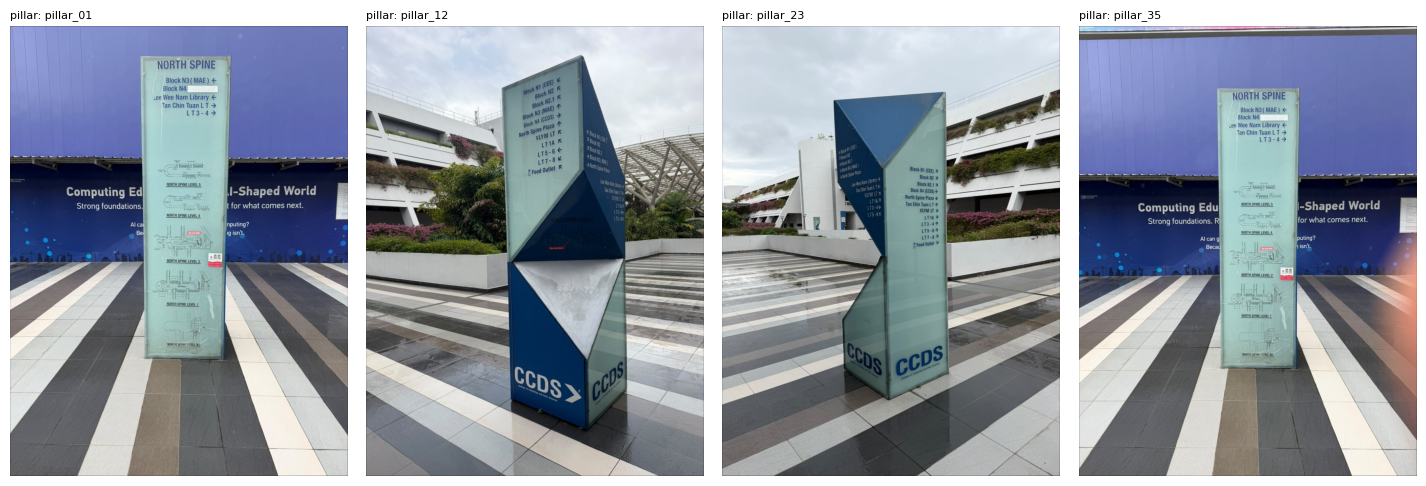

In [ ]:
# Stage 3a (skipped when RECOMPUTE = False: masks come from the saved backup)
if RECOMPUTE:
    RECT        = (0.10, 0.01, 0.80, 0.98)   # GrabCut start box as fractions of the image (x, y, width, height):
                                             # it must contain the whole building; the trees outside it teach GrabCut
    ERODE_PX    = 6                          # shrink the mask so silhouette edges against the sky are not used
    MASK_WORK_W = 600                        # GrabCut runs at this width (faster); the mask is scaled back up
    OUT3        = "/content/stage3_features"
    MASK_DIR    = f"{OUT3}/masks"

    def building_mask(bgr):
        """255 on the building, 0 on sky / trees / ground. Returns (mask, grabcut_ok)."""
        h, w = bgr.shape[:2]
        if not USE_MASK:  # generalisation scenes: use every pixel
            return np.full((h, w), 255, np.uint8), True
        small = cv2.resize(bgr, (MASK_WORK_W, int(h * MASK_WORK_W / w)), interpolation=cv2.INTER_AREA)
        sh, sw = small.shape[:2]
        rect = (int(RECT[0] * sw), int(RECT[1] * sh), int(RECT[2] * sw), int(RECT[3] * sh))
        gc = np.zeros((sh, sw), np.uint8)
        try:
            cv2.grabCut(small, gc, rect, np.zeros((1, 65)), np.zeros((1, 65)), 5, cv2.GC_INIT_WITH_RECT)
            m = np.where((gc == 1) | (gc == 3), 255, 0).astype(np.uint8)
        except cv2.error:
            m = np.zeros((sh, sw), np.uint8)
        m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((7, 7), np.uint8))   # remove specks
        m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))# fill small holes
        n, lab, stats, _ = cv2.connectedComponentsWithStats(m)
        if n > 1:    # keep only the biggest region
            m = np.where(lab == 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA]), 255, 0).astype(np.uint8)
        ok = 0.15 < (m > 0).mean() < 0.90
        if not ok:            # GrabCut failed, so using the start box
            m = np.zeros((sh, sw), np.uint8)
            cv2.rectangle(m, rect[:2], (rect[0] + rect[2], rect[1] + rect[3]), 255, -1)
        m = cv2.resize(m, (w, h), interpolation=cv2.INTER_NEAREST)
        if ERODE_PX:
            m = cv2.erode(m, np.ones((2 * ERODE_PX + 1, 2 * ERODE_PX + 1), np.uint8))
        return m, ok

    shutil.rmtree(MASK_DIR, ignore_errors=True)
    masks = {}  # masks[scene][image name] = uint8 array, 255 = building
    for tag, S in stage2.items():
        os.makedirs(f"{MASK_DIR}/{tag}")
        masks[tag], shares, fallback = {}, [], []
        for nm in S["names"]:
            mask, ok = building_mask(cv2.imread(f"{S['color_dir']}/{nm}.jpg"))
            if not ok: fallback.append(nm)
            masks[tag][nm] = mask; shares.append((mask > 0).mean())
            cv2.imwrite(f"{MASK_DIR}/{tag}/{nm}.png", mask)
        print(f"{tag}: {len(masks[tag])}/{len(S['names'])} masks | covers {min(shares):.0%}-{max(shares):.0%} "
              f"of the image (mean {np.mean(shares):.0%})")
        if fallback:
            print(f"   WARNING: GrabCut failed on {len(fallback)} images, start box used instead: {fallback[:8]}")

    #CHECK A PICTURE: red indicates the removed by the mask
    SHOW = 4
    fig, axes = plt.subplots(len(stage2), SHOW, figsize=(3.6 * SHOW, 4.8 * len(stage2)), squeeze=False)
    for row, (tag, S) in zip(axes, stage2.items()):
        for ax, i in zip(row, np.linspace(0, len(S["names"]) - 1, SHOW).astype(int)):
            nm = S["names"][i]
            img = cv2.cvtColor(cv2.imread(f"{S['color_dir']}/{nm}.jpg"), cv2.COLOR_BGR2RGB)
            out = masks[tag][nm] == 0
            img[out] = (img[out] * 0.3 + np.array([200, 0, 0]) * 0.7).astype(np.uint8)
            ax.imshow(img); ax.set_title(f"{tag}: {nm}", fontsize=8, loc="left"); ax.axis("off")
    plt.tight_layout(); plt.show()

Stage 3b : comparision code for SIFT vs RootSIFT vs ORB

In [ ]:
# Stage 3b (runs when RECOMPUTE = True, or when RUN_FEATURE_COMPARISON = True in the first code cell)
if RUN_FEATURE_COMPARISON:
    if not RECOMPUTE and not globals().get("masks"):      # resume mode: the masks live in the saved backup
        _b = resolve_backup()
        masks = {t: {nm: cv2.imread(f"{_b}/stage3_features/masks/{t}/{nm}.png", cv2.IMREAD_GRAYSCALE) for nm in S_["names"]} for t, S_ in stage2.items()}
    N_FEAT      = 8000                 # same cap for every method (fair comparison)
    GAPS        = [1, 2, 5]            # image i vs i+1, i+2, i+5: a bigger gap means a wider baseline
    SAMPLE_STEP = 3                    # first image of a pair = every 3rd image (1 = use every image)
    RATIO       = {"SIFT": 0.75, "RootSIFT": 0.75, "ORB": 0.80}   # Lowe ratio test per method
    MIN_INLIERS = 30                   # a pair counts as "success" at or above this many inliers
    H, W        = 1600, 1200           # working image size (for the coverage grid)
    OUT_CSV     = "/content/feature_comparison.csv"

    sift = cv2.SIFT_create(nfeatures=N_FEAT)
    orb  = cv2.ORB_create(nfeatures=N_FEAT)

    def root_sift(d):# L1-normalise, then square root
        return np.sqrt(d / (np.abs(d).sum(axis=1, keepdims=True) + 1e-7)).astype(np.float32)

    cache, t_detect = {}, {"SIFT": [], "ORB": []}
    def features(base, path, mask):  # detect once per image and method, then reuse
        if (base, path) not in cache:
            img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
            t = time.perf_counter()
            k, d = (orb if base == "ORB" else sift).detectAndCompute(img, mask)
            t_detect[base].append(time.perf_counter() - t)
            cache[(base, path)] = (np.float32([p.pt for p in k]), d)
        return cache[(base, path)]

    def ratio_matches(method, d1, d2):
        knn = cv2.BFMatcher(cv2.NORM_HAMMING if method == "ORB" else cv2.NORM_L2).knnMatch(d1, d2, k=2)
        return [p[0] for p in knn if len(p) == 2 and p[0].distance < RATIO[method] * p[1].distance]

    rows = []
    for tag, S in stage2.items():
        names = S["names"]
        for i in range(0, len(names), SAMPLE_STEP):
            for g in GAPS:
                j = i + g
                if j >= len(names):
                    continue
                p1, p2 = (f"{S['gray_dir']}/{names[n]}.png" for n in (i, j))
                for method in RATIO:
                    base = "ORB" if method == "ORB" else "SIFT"
                    (x1, d1), (x2, d2) = features(base, p1, masks[tag][names[i]]), features(base, p2, masks[tag][names[j]])
                    if d1 is None or d2 is None or len(d1) < 2 or len(d2) < 2:
                        continue
                    if method == "RootSIFT":
                        d1, d2 = root_sift(d1), root_sift(d2)
                    t = time.perf_counter()
                    good = ratio_matches(method, d1, d2)
                    t_match = time.perf_counter() - t
                    inl, cover = 0, 0.0
                    if len(good) >= 8:
                        a = x1[[m.queryIdx for m in good]]
                        b = x2[[m.trainIdx for m in good]]
                        F, mask = cv2.findFundamentalMat(a, b, cv2.FM_RANSAC, 1.0, 0.999, 10000)
                        if mask is not None and F is not None:
                            mask = mask.ravel().astype(bool)
                            inl = int(mask.sum())
                            if inl:    # share of a 4x4 grid holding inliers
                                gx = np.clip((a[mask, 0] / W * 4).astype(int), 0, 3)
                                gy = np.clip((a[mask, 1] / H * 4).astype(int), 0, 3)
                                cover = len(set(zip(gx, gy))) / 16
                    rows.append(dict(scene=tag, gap=g, method=method, kp=len(x1), ratio_matches=len(good),
                                     inliers=inl, inlier_ratio=inl / max(len(good), 1),
                                     coverage=cover, t_match=t_match))

    df = pd.DataFrame(rows)
    df["success"] = df.inliers >= MIN_INLIERS
    summary = (df.groupby(["scene", "gap", "method"])
                 .agg(pairs=("inliers", "size"), keypoints=("kp", "mean"), matches=("ratio_matches", "mean"),
                      inliers=("inliers", "mean"), inlier_ratio=("inlier_ratio", "mean"),
                      coverage=("coverage", "mean"), success=("success", "mean"), t_match_s=("t_match", "mean"))
                 .round(2))
    print(summary.to_string())
    print("\ndetection time per image (s):", {m: round(float(np.mean(v)), 3) for m, v in t_detect.items() if v},
          "(RootSIFT = SIFT)")
    df.to_csv(OUT_CSV, index=False)
    shutil.copy(OUT_CSV, f"{PROJECT}/feature_comparison.csv"); summary.to_csv(f"{PROJECT}/feature_comparison_summary.csv")

    #chart: mean RANSAC inliers per method, one panel per scene
    COLORS = {"SIFT": "#2a78d6", "RootSIFT": "#eb6834", "ORB": "#1baf7a"}   # fixed order, validated palette
    fig, axes = plt.subplots(1, len(stage2), figsize=(5.5 * len(stage2), 4), sharey=True, squeeze=False)
    for ax, tag in zip(axes[0], stage2):
        piv = (df[df.scene == tag].pivot_table(index="gap", columns="method", values="inliers", aggfunc="mean")
                 .reindex(columns=list(RATIO)))
        piv.plot.bar(ax=ax, color=[COLORS[m] for m in piv.columns], width=0.75, edgecolor="white", linewidth=1.5)
        ax.set_title(tag, loc="left", fontsize=11)
        ax.set_xlabel("image gap (1 = neighbours, 5 = wide baseline)")
        ax.tick_params(axis="x", rotation=0)
        ax.grid(axis="y", alpha=0.25); ax.set_axisbelow(True)
        for s in ("top", "right"): ax.spines[s].set_visible(False)
        ax.set_ylim(0, max(df.groupby(["scene", "gap", "method"]).inliers.mean().max() * 1.25, 1))   # headroom for the legend
        ax.legend(frameon=False, fontsize=9, ncol=3, loc="upper center")
    axes[0][0].set_ylabel("mean RANSAC inliers per pair")
    plt.tight_layout(); plt.show()

Stage 3c : final feature extraction on the building only. Implementing RootSIFT as it wins in the comparision

pillar: 35/35 images | keypoints min 2500  mean 2500  max 2501
   fewest keypoints: pillar_01 (2500), pillar_03 (2500), pillar_04 (2500)

method = SIFT + RootSIFT; Stage 4 matcher norm: cv2.NORM_L2


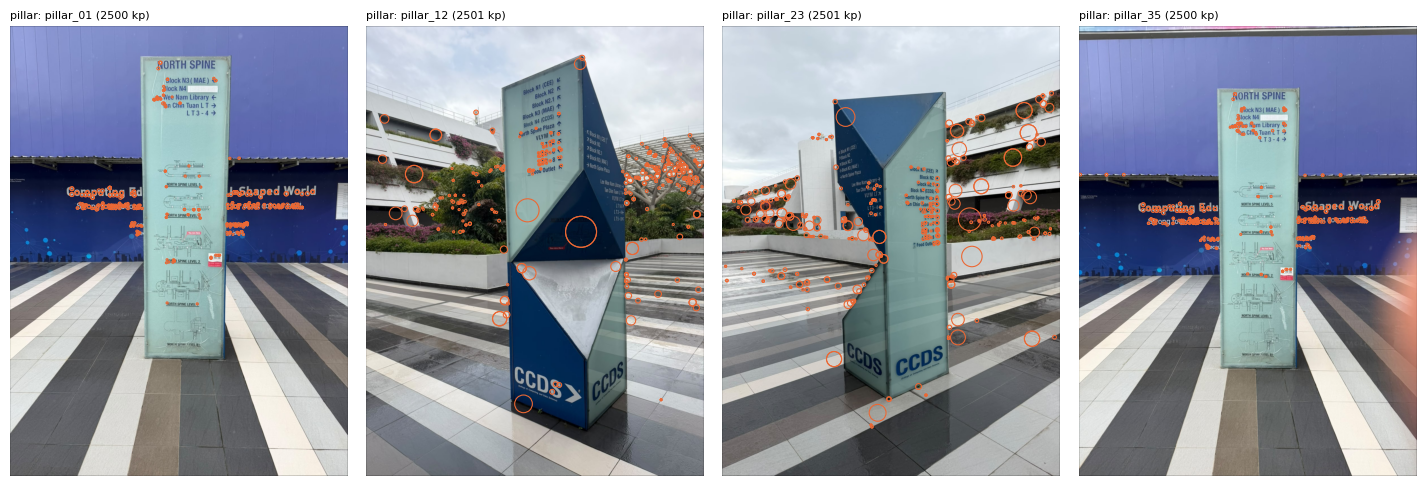

In [ ]:
# Stage 3c (skipped when RECOMPUTE = False)
if RECOMPUTE:
    METHOD   = "SIFT"          # "SIFT" or "ORB"  (set from the comparison result)
    ROOTSIFT = True            # RootSIFT descriptors (SIFT only)
    N_FEAT   = 2500            # upper limit per image (no mask here, so SIFT would otherwise keep 8000 and matching gets slow)
    CONTRAST = 0.02            # SIFT only: lower = more keypoints on plain walls
    BOUNDARY = 0.5             # drop keypoints closer to the mask edge than BOUNDARY x their size (0 = keep all)
    OUT3     = "/content/stage3_features"

    if METHOD == "SIFT":
        detector, NORM = cv2.SIFT_create(nfeatures=N_FEAT, contrastThreshold=CONTRAST), cv2.NORM_L2
    else:
        detector, NORM = cv2.ORB_create(nfeatures=N_FEAT), cv2.NORM_HAMMING

    def get_mask(tag, nm):                      # from 3a, in memory or from the saved png
        m = masks.get(tag, {}).get(nm)
        if m is None:
            m = cv2.imread(f"{OUT3}/masks/{tag}/{nm}.png", cv2.IMREAD_GRAYSCALE)
        if m is None:
            raise FileNotFoundError(f"no mask for {tag}/{nm} - run Stage 3a first")
        return m

    features = {}  # features[scene][name] = dict(pts, size, angle, response, desc)
    for tag, S in stage2.items():
        shutil.rmtree(f"{OUT3}/{tag}", ignore_errors=True) # only the keypoint files; masks are kept
        os.makedirs(f"{OUT3}/{tag}")
        features[tag], counts = {}, {}
        for nm in S["names"]:
            mask = get_mask(tag, nm)
            gray = cv2.imread(f"{S['gray_dir']}/{nm}.png", cv2.IMREAD_GRAYSCALE)
            k, d = detector.detectAndCompute(gray, mask)# only looks inside the mask
            if d is None or len(k) == 0:
                print("WARNING no features in", tag, nm); continue
            if BOUNDARY > 0:  # the keypoint's patch must stay on the building
                dist = cv2.distanceTransform((mask > 0).astype(np.uint8), cv2.DIST_L2, 3)
                xs = np.clip(np.round([p.pt[0] for p in k]).astype(int), 0, mask.shape[1] - 1)
                ys = np.clip(np.round([p.pt[1] for p in k]).astype(int), 0, mask.shape[0] - 1)
                keep = dist[ys, xs] >= BOUNDARY * np.array([p.size for p in k])
                k, d = [p for p, f in zip(k, keep) if f], d[keep]
                if len(k) == 0:
                    print("WARNING no features left in", tag, nm); continue
            if METHOD == "SIFT" and ROOTSIFT:
                d = np.sqrt(d / (np.abs(d).sum(axis=1, keepdims=True) + 1e-7)).astype(np.float32)
            rec = dict(pts=np.float32([p.pt for p in k]), size=np.float32([p.size for p in k]),
                       angle=np.float32([p.angle for p in k]), response=np.float32([p.response for p in k]),
                       desc=d)
            features[tag][nm] = rec
            np.savez_compressed(f"{OUT3}/{tag}/{nm}.npz", **rec)
            counts[nm] = len(k)
        c = np.array(list(counts.values())); weakest = sorted(counts, key=counts.get)[:3]
        print(f"{tag}: {len(c)}/{len(S['names'])} images | keypoints min {c.min()}  mean {c.mean():.0f}  max {c.max()}")
        print(f"   fewest keypoints: {', '.join(f'{w} ({counts[w]})' for w in weakest)}")

    print(f"\nmethod = {METHOD}{' + RootSIFT' if METHOD == 'SIFT' and ROOTSIFT else ''}; "
          f"Stage 4 matcher norm: {'cv2.NORM_L2' if NORM == cv2.NORM_L2 else 'cv2.NORM_HAMMING'}")

    #CHECK A PICTURE: red indicates the removed by the mask, orange circles = strongest 400 keypoints
    SHOW = 4
    fig, axes = plt.subplots(len(stage2), SHOW, figsize=(3.6 * SHOW, 4.8 * len(stage2)), squeeze=False)
    for row, (tag, S) in zip(axes, stage2.items()):
        for ax, i in zip(row, np.linspace(0, len(S["names"]) - 1, SHOW).astype(int)):
            nm = S["names"][i]; r = features[tag][nm]
            img = cv2.cvtColor(cv2.imread(f"{S['color_dir']}/{nm}.jpg"), cv2.COLOR_BGR2RGB)
            out = get_mask(tag, nm) == 0
            img[out] = (img[out] * 0.3 + np.array([200, 0, 0]) * 0.7).astype(np.uint8)
            top = np.argsort(-r["response"])[:400]
            ax.imshow(img)
            ax.scatter(r["pts"][top, 0], r["pts"][top, 1], s=r["size"][top] ** 1.2, facecolors="none",
                       edgecolors="#eb6834", linewidths=0.8)
            ax.set_title(f"{tag}: {nm} ({len(r['pts'])} kp)", fontsize=8, loc="left"); ax.axis("off")
    plt.tight_layout(); plt.show()

### Stage 4 check: are the far-apart accepted pairs real?

The tower has four sides that look almost the same: the same roof edge, the same decorated band, the same railing. So the matcher sometimes pairs a photo of one side with a photo of a different side, and those pairs look correct even though they are wrong.

This cell checks that. It does two things:

Prints how many photo pairs matched, grouped by how far apart the photos were taken.
Draws three far-apart pairs with lines between the matched points, so you can see with your own eyes whether the lines join the same part of the tower.

What we found: the weak far pairs (about 30-40 matches) joined different sides and were wrong, and the strong ones (hundreds of matches) were real. This is why the next cell removes weak far-apart pairs.



pillar: accepted pairs by index gap and by loop gap (the shorter way round)
   by gap      1-1: 34/34 (ratio 0.75) | 2-5: 97/126 (ratio 0.68) | 6-10: 20/135 (ratio 0.61) | 11-20: 34/195 (ratio 0.54) | 21-27: 15/77 (ratio 0.46) | 28-99: 27/28 (ratio 0.68)
   by loop_gap 1-1: 35/35 (ratio 0.75) | 2-5: 111/140 (ratio 0.68) | 6-10: 40/175 (ratio 0.60) | 11-20: 41/245 (ratio 0.52)


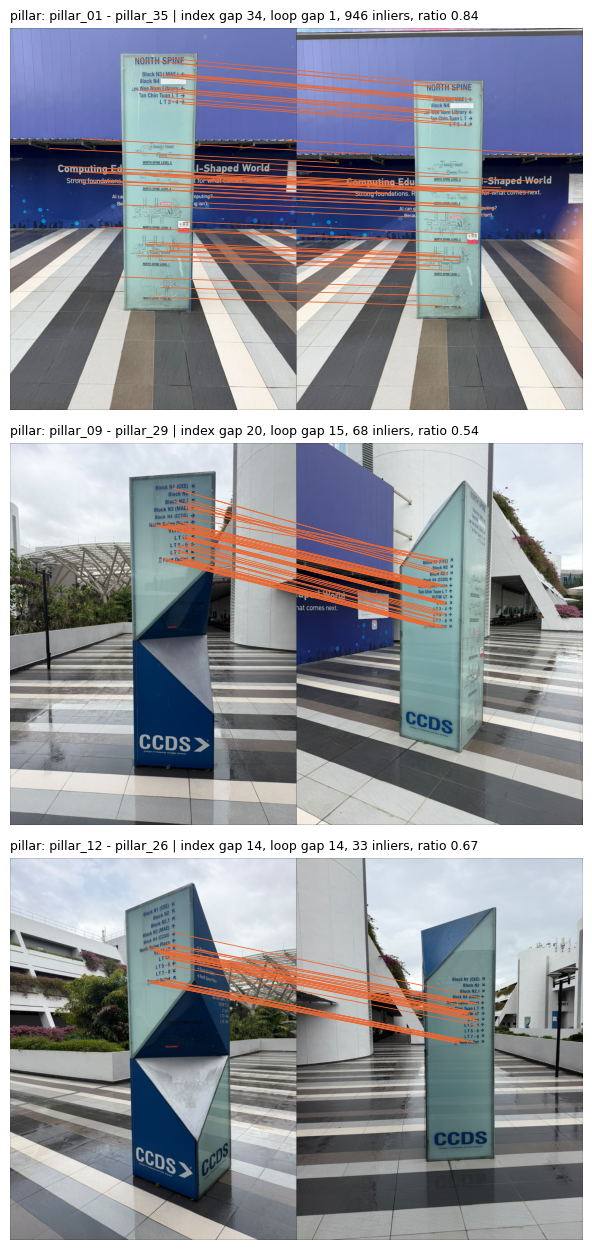

In [ ]:
# Stage 4 check (skipped when RECOMPUTE = False)
if RECOMPUTE:
    import numpy as np, cv2, matplotlib.pyplot as plt
    FAR = 10                                            # "far" = index gap above this
    for tag, S in stage2.items():
        names, n = S["names"], len(S["names"])
        df = pair_info[tag].copy()
        df["loop_gap"] = loopgap(df.gap, n, tag)  # distance if the images form a closed loop
        print(f"\n{tag}: accepted pairs by index gap and by loop gap (the shorter way round)")
        bins = [(1, 1), (2, 5), (6, 10), (11, 20), (21, 27), (28, 99)]
        for col in ("gap", "loop_gap"):
            out = []
            for lo, hi in bins:
                d = df[df[col].between(lo, hi)]
                if len(d): out.append(f"{lo}-{hi}: {int(d.accepted.sum())}/{len(d)}"
                                      f" (ratio {d[d.accepted].inlier_ratio.mean():.2f})" if d.accepted.any() else f"{lo}-{hi}: 0/{len(d)}")
            print(f"   by {col:8s} " + " | ".join(out))
        far = df[(df.gap > FAR) & df.accepted].sort_values("inliers", ascending=False)
        picks = [far.iloc[0], far.iloc[len(far) // 2], far.iloc[-1]] if len(far) else []
        fig, axes = plt.subplots(len(picks), 1, figsize=(10, 4.2 * max(len(picks), 1)), squeeze=False)
        for ax, r in zip(axes[:, 0], picks):
            i, j = int(r.i), int(r.j)
            a = cv2.cvtColor(cv2.imread(f"{S['color_dir']}/{names[i]}.jpg"), cv2.COLOR_BGR2RGB)
            b = cv2.cvtColor(cv2.imread(f"{S['color_dir']}/{names[j]}.jpg"), cv2.COLOR_BGR2RGB)
            ax.imshow(np.hstack([a, b])); w = a.shape[1]
            m = matches[tag][(i, j)]; sel = np.random.default_rng(0).choice(len(m), min(60, len(m)), replace=False)
            for p, q in zip(features[tag][names[i]]["pts"][m[sel, 0]], features[tag][names[j]]["pts"][m[sel, 1]]):
                ax.plot([p[0], q[0] + w], [p[1], q[1]], lw=0.6, color="#eb6834")
            ax.set_title(f"{tag}: {names[i]} - {names[j]} | index gap {int(r.gap)}, loop gap {int(r.loop_gap)}, "
                         f"{int(r.inliers)} inliers, ratio {r.inlier_ratio:.2f}", fontsize=9, loc="left"); ax.axis("off")
        plt.tight_layout(); plt.show()

Stage 4a : Feature matching, geometric verification, connectivity graph, tracks


pillar: 35 images, 595 pairs to match (every pair)
   300/595 pairs  (177s, about 174s left)
   matching done in 345s
   accepted pairs: 227/595 (38%) | mean inliers of accepted 180 | mean inlier ratio 0.65
   accepted by image gap:  1: 34/34   2-5: 97/126   6-10: 20/135   >10: 76/300
   graph: 1 connected part(s), sizes [35] | partners per image: min 8, mean 13.0
   neighbours (i, i+1) NOT matched: 0 []
   weakly connected images (< 3 partners): []
   tracks: 9389 kept (length >= 2), 4514 with >= 3 views | mean length 3.4, max 19 | dropped 177 of 9566 chains (two keypoints in one image)
   best starting pairs:
       img_i      img_j  inliers  inlier_ratio  homography_ratio  median_disp_px  start_score
0  pillar_01  pillar_35      946          0.84              0.54           55.59        437.0
1  pillar_32  pillar_33      721          0.84              0.51           35.26        352.0
2  pillar_31  pillar_32      599          0.79              0.42          153.21        348.0
3  p

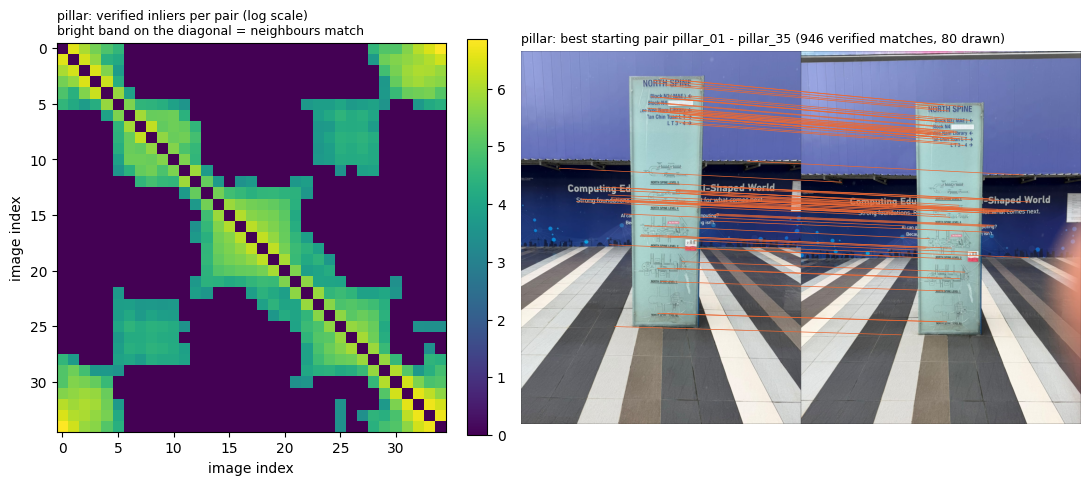


saved to /content/stage4_matches  (pair_info.csv, matches.npz, tracks.npz, inlier_matrix.npy, start_pairs.csv, settings.json)
in memory: matches[scene][(i, j)] = (m, 2) keypoint indices | pair_info[scene] | graph[scene] | tracks[scene] | start_pairs[scene]


In [ ]:
# Stage 4a (skipped when RECOMPUTE = False)
if RECOMPUTE:
    import os, json, time, itertools, shutil, cv2, numpy as np, pandas as pd
    import matplotlib.pyplot as plt
    from scipy.sparse import coo_matrix, csr_matrix
    from scipy.sparse.csgraph import connected_components

    RATIO       = 0.75 if NORM == cv2.NORM_L2 else 0.80   # Lowe ratio test: best match must beat the 2nd best by this factor
    MUTUAL      = True       # keep a match only if it is also the nearest neighbour in the opposite direction
    RANSAC_PX   = 1.0        # a match is an inlier if it lies within this many pixels of its epipolar line
    MIN_INLIERS = 30         # a pair is accepted at or above this many verified matches
    H_PX        = 3.0        # homography tolerance (used only to score pairs for initialisation)
    MIN_DISP    = 30.0       # start pairs need this median pixel displacement (some baseline)
    MIN_TRACK   = 2          # shortest track kept (views)
    WEAK_DEG    = 3          # an image with fewer accepted partners than this is called weakly connected
    TOP_START   = 10         # how many candidate starting pairs to list
    OUT4        = "/content/stage4_matches"


    shutil.rmtree(OUT4, ignore_errors=True); os.makedirs(OUT4)
    matches, pair_info, graph, tracks, start_pairs = {}, {}, {}, {}, {}

    def match_descriptors(da, db):
        """ratio test (+ mutual check). Returns index arrays ia, ib into the two keypoint lists."""
        bf = cv2.BFMatcher(NORM)
        ia, ib = [], []
        for p in bf.knnMatch(da, db, k=2):
            if len(p) == 2 and p[0].distance < RATIO * p[1].distance:
                ia.append(p[0].queryIdx); ib.append(p[0].trainIdx)
        ia, ib = np.array(ia, int), np.array(ib, int)
        if MUTUAL and len(ia):
            nn = np.full(len(db), -1)
            for m in bf.match(db, da):
                nn[m.queryIdx] = m.trainIdx
            keep = nn[ib] == ia
            ia, ib = ia[keep], ib[keep]
        return ia, ib

    def verify_pair(pa, pb):
        """fundamental-matrix RANSAC. Returns inlier mask, homography share, median displacement."""
        cv2.setRNGSeed(0)# same result on every run
        F, m = cv2.findFundamentalMat(pa, pb, cv2.FM_RANSAC, RANSAC_PX, 0.999, 5000)
        if F is None or m is None or F.shape != (3, 3):
            return None, np.nan, np.nan
        inl = m.ravel().astype(bool)
        n = int(inl.sum())
        if n < 8:
            return inl, np.nan, np.nan
        cv2.setRNGSeed(0)
        H, hm = cv2.findHomography(pa[inl], pb[inl], cv2.RANSAC, H_PX)
        hratio = float(hm.sum()) / n if hm is not None else np.nan
        disp = float(np.median(np.linalg.norm(pb[inl] - pa[inl], axis=1)))
        return inl, hratio, disp

    for tag, S in stage2.items():
        names, n = S["names"], len(S["names"])
        feats = [features[tag][nm] for nm in names]
        pairs = list(itertools.combinations(range(n), 2))
        print(f"\n{tag}: {n} images, {len(pairs)} pairs to match (every pair)")
        M, rows, t0 = {}, [], time.perf_counter()
        for c, (i, j) in enumerate(pairs):
            fa, fb = feats[i], feats[j]
            ia, ib = match_descriptors(fa["desc"], fb["desc"])
            nraw, ninl, hr, disp = len(ia), 0, np.nan, np.nan
            if nraw >= 8:
                inl, hr, disp = verify_pair(fa["pts"][ia], fb["pts"][ib])
                if inl is not None:
                    ninl = int(inl.sum())
                    if ninl >= MIN_INLIERS:
                        M[(i, j)] = np.stack([ia[inl], ib[inl]], 1).astype(np.int32)
            acc = ninl >= MIN_INLIERS
            score = ninl * (1 - hr) if (acc and disp >= MIN_DISP and not np.isnan(hr)) else 0.0
            rows.append(dict(i=i, j=j, img_i=names[i], img_j=names[j], gap=j - i, matches=nraw, inliers=ninl,
                             inlier_ratio=ninl / max(nraw, 1), homography_ratio=hr, median_disp_px=disp,
                             accepted=acc, start_score=score))
            if (c + 1) % 300 == 0:
                el = time.perf_counter() - t0
                print(f"   {c + 1}/{len(pairs)} pairs  ({el:.0f}s, about {el / (c + 1) * (len(pairs) - c - 1):.0f}s left)")
        matches[tag] = M
        df = pd.DataFrame(rows); pair_info[tag] = df
        print(f"   matching done in {time.perf_counter() - t0:.0f}s")

        # connectivity graph
        W = np.zeros((n, n), int)
        for r in df[df.accepted].itertuples():
            W[r.i, r.j] = W[r.j, r.i] = r.inliers
        ncomp, comp = connected_components(csr_matrix(W > 0), directed=False)
        deg = (W > 0).sum(1)
        weak = [names[k] for k in np.where(deg < WEAK_DEG)[0]]
        graph[tag] = dict(inliers=W, components=comp, degree=deg, weak=weak, names=names)

        #tracks: chain the verified matches together
        offs = np.concatenate([[0], np.cumsum([len(f["pts"]) for f in feats])])
        if M:
            ea = np.concatenate([offs[i] + m[:, 0] for (i, j), m in M.items()])
            eb = np.concatenate([offs[j] + m[:, 1] for (i, j), m in M.items()])
            N = int(offs[-1])
            _, lab = connected_components(coo_matrix((np.ones(len(ea)), (ea, eb)), shape=(N, N)), directed=False)
            used = np.unique(np.concatenate([ea, eb]))
            img_of = np.searchsorted(offs, used, side="right") - 1
            kp_of = used - offs[img_of]
            lab_u = lab[used]
            o = np.lexsort((img_of, lab_u)); lab_s, img_s, kp_s = lab_u[o], img_of[o], kp_of[o]
            same = (lab_s[1:] == lab_s[:-1]) & (img_s[1:] == img_s[:-1])      # two keypoints of one image in one track
            bad = np.unique(lab_s[1:][same])
            n_all = len(np.unique(lab_s)); n_bad = len(bad)
            ok = ~np.isin(lab_s, bad)
            lab_s, img_s, kp_s = lab_s[ok], img_s[ok], kp_s[ok]
            _, start, cnt = np.unique(lab_s, return_index=True, return_counts=True)
            long_ = cnt >= MIN_TRACK
            sel = np.concatenate([np.arange(s, s + c_) for s, c_ in zip(start[long_], cnt[long_])]) if long_.any() else np.array([], int)
            ptr = np.concatenate([[0], np.cumsum(cnt[long_])])
            tracks[tag] = dict(ptr=ptr, img=img_s[sel].astype(np.int32), kp=kp_s[sel].astype(np.int32), names=names)
            tl = cnt[long_]
        else:
            n_all = n_bad = 0; tl = np.array([], int)
            tracks[tag] = dict(ptr=np.array([0]), img=np.array([], np.int32), kp=np.array([], np.int32), names=names)

        #candidate starting pairs for Stage 5
        sp = df[df.start_score > 0].sort_values("start_score", ascending=False).head(TOP_START)
        start_pairs[tag] = sp[["img_i", "img_j", "inliers", "inlier_ratio", "homography_ratio",
                               "median_disp_px", "start_score"]].round(2).reset_index(drop=True)

        #report
        acc = df[df.accepted]
        print(f"   accepted pairs: {len(acc)}/{len(df)} ({len(acc) / len(df):.0%}) | mean inliers of accepted {acc.inliers.mean():.0f}"
              f" | mean inlier ratio {acc.inlier_ratio.mean():.2f}")
        print(f"   accepted by image gap:  1: {(acc.gap == 1).sum()}/{(df.gap == 1).sum()}   2-5: "
              f"{acc.gap.between(2, 5).sum()}/{df.gap.between(2, 5).sum()}   6-10: {acc.gap.between(6, 10).sum()}/"
              f"{df.gap.between(6, 10).sum()}   >10: {(acc.gap > 10).sum()}/{(df.gap > 10).sum()}")
        print(f"   graph: {ncomp} connected part(s), sizes {sorted((int(x) for x in np.bincount(comp)), reverse=True)} | "
              f"partners per image: min {deg.min()}, mean {deg.mean():.1f}")
        failed_nb = [f"{names[k]}-{names[k + 1]}" for k in range(n - 1) if W[k, k + 1] == 0]
        print(f"   neighbours (i, i+1) NOT matched: {len(failed_nb)} {failed_nb[:8]}")
        print(f"   weakly connected images (< {WEAK_DEG} partners): {weak}")
        if len(tl):
            print(f"   tracks: {len(tl)} kept (length >= {MIN_TRACK}), {int((tl >= 3).sum())} with >= 3 views | mean length "
                  f"{tl.mean():.1f}, max {tl.max()} | dropped {n_bad} of {n_all} chains (two keypoints in one image)")
        print(f"   best starting pairs:\n{start_pairs[tag].head(5).to_string()}")

        #save
        os.makedirs(f"{OUT4}/{tag}")
        np.savez_compressed(f"{OUT4}/{tag}/matches.npz", **{f"{i}_{j}": m for (i, j), m in M.items()})
        df.to_csv(f"{OUT4}/{tag}/pair_info.csv", index=False)
        np.save(f"{OUT4}/{tag}/inlier_matrix.npy", W)
        t_ = tracks[tag]; np.savez_compressed(f"{OUT4}/{tag}/tracks.npz", ptr=t_["ptr"], img=t_["img"], kp=t_["kp"])
        start_pairs[tag].to_csv(f"{OUT4}/{tag}/start_pairs.csv", index=False)
        open(f"{OUT4}/{tag}/image_names.txt", "w").write("\n".join(names))

    json.dump(dict(opencv=cv2.__version__, norm="L2" if NORM == cv2.NORM_L2 else "HAMMING", ratio=RATIO, mutual=MUTUAL,
                   ransac_px=RANSAC_PX, min_inliers=MIN_INLIERS, min_track=MIN_TRACK, method=globals().get("METHOD"),
                   rootsift=globals().get("ROOTSIFT"), contrast=globals().get("CONTRAST"), boundary=globals().get("BOUNDARY"),
                   images={t: len(S["names"]) for t, S in stage2.items()}),
              open(f"{OUT4}/settings.json", "w"), indent=1)

    def track_points(tag, t):
        """one track as [(image name, x, y), ...]"""
        T = tracks[tag]; a, b = T["ptr"][t], T["ptr"][t + 1]
        return [(T["names"][i], *features[tag][T["names"][i]]["pts"][k]) for i, k in zip(T["img"][a:b], T["kp"][a:b])]

    #CHECK A PICTURE: left indicates the inlier counts between all image pairs, right = best starting pair
    fig, axes = plt.subplots(len(stage2), 2, figsize=(11, 5.2 * len(stage2)), squeeze=False,
                             gridspec_kw=dict(width_ratios=[1, 1.3]))
    for (ax1, ax2), (tag, S) in zip(axes, stage2.items()):
        W = graph[tag]["inliers"]; names = S["names"]
        im = ax1.imshow(np.log1p(W), cmap="viridis")
        ax1.set_title(f"{tag}: verified inliers per pair (log scale)\nbright band on the diagonal = neighbours match", fontsize=9, loc="left")
        ax1.set_xlabel("image index"); ax1.set_ylabel("image index"); plt.colorbar(im, ax=ax1, fraction=0.046)
        if len(start_pairs[tag]):
            r = start_pairs[tag].iloc[0]; i, j = names.index(r.img_i), names.index(r.img_j)
            a = cv2.cvtColor(cv2.imread(f"{S['color_dir']}/{names[i]}.jpg"), cv2.COLOR_BGR2RGB)
            b = cv2.cvtColor(cv2.imread(f"{S['color_dir']}/{names[j]}.jpg"), cv2.COLOR_BGR2RGB)
            ax2.imshow(np.hstack([a, b])); w = a.shape[1]
            m = matches[tag][(i, j)]; sel = np.random.default_rng(0).choice(len(m), min(80, len(m)), replace=False)
            pa, pb = features[tag][names[i]]["pts"][m[sel, 0]], features[tag][names[j]]["pts"][m[sel, 1]]
            for p, q in zip(pa, pb):
                ax2.plot([p[0], q[0] + w], [p[1], q[1]], lw=0.5, color="#eb6834")
            ax2.set_title(f"{tag}: best starting pair {names[i]} - {names[j]} ({len(m)} verified matches, 80 drawn)", fontsize=9, loc="left")
        ax2.axis("off")
    plt.tight_layout(); plt.show()
    print(f"\nsaved to {OUT4}  (pair_info.csv, matches.npz, tracks.npz, inlier_matrix.npy, start_pairs.csv, settings.json)")
    print("in memory: matches[scene][(i, j)] = (m, 2) keypoint indices | pair_info[scene] | graph[scene] | tracks[scene] | start_pairs[scene]")

Stage 4b: stricter rule for far-apart pairs, then rebuild graph + tracks (no re-matching)

In [ ]:
# Stage 4b (skipped when RECOMPUTE = False)
if RECOMPUTE:
    import os, json, numpy as np, pandas as pd
    from scipy.sparse import coo_matrix, csr_matrix
    from scipy.sparse.csgraph import connected_components

    FAR_LOOP        = 5     # pairs further apart than this (the shorter way round the loop) get the stricter rule
    FAR_MIN_INLIERS = 60    # far pairs need at least this many verified matches ...
    MIN_CELLS       = 5     # ... spread over at least this many of the 4x4 image cells (in both images)
    FAR_STRONG      = 120   # far pairs with at least this many verified matches are kept whatever their spread
    IMG_W, IMG_H    = 1200, 1600

    if "matches_raw" not in globals():        # keeping the 4a result so this cell can be rerun with other numbers
        matches_raw = {t: dict(m) for t, m in matches.items()}
        pair_raw    = {t: d.copy() for t, d in pair_info.items()}

    def cells(p):
        gx = np.clip((p[:, 0] / IMG_W * 4).astype(int), 0, 3); gy = np.clip((p[:, 1] / IMG_H * 4).astype(int), 0, 3)
        return len(set(zip(gx.tolist(), gy.tolist())))

    for tag, S in stage2.items():
        names, n = S["names"], len(S["names"])
        feats = [features[tag][nm] for nm in names]
        df = pair_raw[tag].copy()
        df["loop_gap"] = loopgap(df.gap, n, tag)
        df["cells"] = 0
        M = {}
        for r in df[df.accepted].itertuples():
            m = matches_raw[tag][(r.i, r.j)]
            c = min(cells(feats[r.i]["pts"][m[:, 0]]), cells(feats[r.j]["pts"][m[:, 1]]))
            df.at[r.Index, "cells"] = c
            if r.loop_gap <= FAR_LOOP or r.inliers >= FAR_STRONG or (r.inliers >= FAR_MIN_INLIERS and c >= MIN_CELLS):
                M[(r.i, r.j)] = m
        df["accepted_raw"] = df.accepted
        df["accepted"] = [(r.i, r.j) in M for r in df.itertuples()]
        ok = df.accepted & (df.median_disp_px >= MIN_DISP) & df.homography_ratio.notna()
        df["start_score"] = np.where(ok, df.inliers * (1 - df.homography_ratio), 0.0)
        matches[tag], pair_info[tag] = M, df

        far_raw = df[df.accepted_raw & (df.loop_gap > FAR_LOOP)]; removed = df[df.accepted_raw & ~df.accepted]
        print(f"\n{tag}: far accepted pairs {len(far_raw)} -> {int((far_raw.accepted).sum())} kept, {len(removed)} removed")
        if len(removed):
            print("   removed pairs with the most inliers (check that none of these is a real loop closure):")
            print(removed.sort_values("inliers", ascending=False).head(5)[["img_i", "img_j", "loop_gap", "inliers", "cells"]].to_string(index=False))

        #graph
        W = np.zeros((n, n), int)
        for r in df[df.accepted].itertuples():
            W[r.i, r.j] = W[r.j, r.i] = r.inliers
        ncomp, comp = connected_components(csr_matrix(W > 0), directed=False)
        deg = (W > 0).sum(1); weak = [names[k] for k in np.where(deg < WEAK_DEG)[0]]
        graph[tag] = dict(inliers=W, components=comp, degree=deg, weak=weak, names=names)

        #tracks
        offs = np.concatenate([[0], np.cumsum([len(f["pts"]) for f in feats])])
        ea = np.concatenate([offs[i] + m[:, 0] for (i, j), m in M.items()]); eb = np.concatenate([offs[j] + m[:, 1] for (i, j), m in M.items()])
        N = int(offs[-1])
        _, lab = connected_components(coo_matrix((np.ones(len(ea)), (ea, eb)), shape=(N, N)), directed=False)
        used = np.unique(np.concatenate([ea, eb])); img_of = np.searchsorted(offs, used, side="right") - 1
        kp_of = used - offs[img_of]; lab_u = lab[used]
        o = np.lexsort((img_of, lab_u)); lab_s, img_s, kp_s = lab_u[o], img_of[o], kp_of[o]
        same = (lab_s[1:] == lab_s[:-1]) & (img_s[1:] == img_s[:-1])
        bad = np.unique(lab_s[1:][same]); n_all, n_bad = len(np.unique(lab_s)), len(bad)
        keep = ~np.isin(lab_s, bad); lab_s, img_s, kp_s = lab_s[keep], img_s[keep], kp_s[keep]
        _, start, cnt = np.unique(lab_s, return_index=True, return_counts=True)
        long_ = cnt >= MIN_TRACK
        sel = np.concatenate([np.arange(s, s + c_) for s, c_ in zip(start[long_], cnt[long_])])
        tracks[tag] = dict(ptr=np.concatenate([[0], np.cumsum(cnt[long_])]), img=img_s[sel].astype(np.int32),
                           kp=kp_s[sel].astype(np.int32), names=names)
        tl = cnt[long_]

        sp = df[df.start_score > 0].sort_values("start_score", ascending=False).head(TOP_START)
        start_pairs[tag] = sp[["img_i", "img_j", "inliers", "inlier_ratio", "homography_ratio",
                               "median_disp_px", "start_score"]].round(2).reset_index(drop=True)

        acc = df[df.accepted]
        print(f"   accepted pairs: {len(acc)}/{len(df)} | mean inliers {acc.inliers.mean():.0f} | mean inlier ratio {acc.inlier_ratio.mean():.2f}")
        print(f"   graph: {ncomp} connected part(s), sizes {sorted((int(x) for x in np.bincount(comp)), reverse=True)} | "
              f"partners per image: min {deg.min()}, mean {deg.mean():.1f} | weakly connected: {weak}")
        print(f"   neighbours (i, i+1) NOT matched: {[f'{names[k]}-{names[k+1]}' for k in range(n-1) if W[k, k+1] == 0]}")
        print(f"   tracks: {len(tl)} kept, {int((tl >= 3).sum())} with >= 3 views | mean length {tl.mean():.1f}, max {tl.max()} | "
              f"dropped {n_bad} of {n_all} chains")
        print(f"   best starting pairs:\n{start_pairs[tag].head(3).to_string()}")

        #save (overwrites the 4a files; the unfiltered matches are kept as matches_raw.npz)
        np.savez_compressed(f"{OUT4}/{tag}/matches_raw.npz", **{f"{i}_{j}": m for (i, j), m in matches_raw[tag].items()})
        np.savez_compressed(f"{OUT4}/{tag}/matches.npz", **{f"{i}_{j}": m for (i, j), m in M.items()})
        df.to_csv(f"{OUT4}/{tag}/pair_info.csv", index=False); np.save(f"{OUT4}/{tag}/inlier_matrix.npy", W)
        t_ = tracks[tag]; np.savez_compressed(f"{OUT4}/{tag}/tracks.npz", ptr=t_["ptr"], img=t_["img"], kp=t_["kp"])
        start_pairs[tag].to_csv(f"{OUT4}/{tag}/start_pairs.csv", index=False)

    cfg = json.load(open(f"{OUT4}/settings.json"))
    cfg.update(far_loop=FAR_LOOP, far_min_inliers=FAR_MIN_INLIERS, min_cells=MIN_CELLS)
    json.dump(cfg, open(f"{OUT4}/settings.json", "w"), indent=1)
    print(f"\nupdated files in {OUT4}")


pillar: far accepted pairs 81 -> 13 kept, 68 removed
   removed pairs with the most inliers (check that none of these is a real loop closure):
    img_i     img_j  loop_gap  inliers  cells
pillar_03 pillar_30         8      117      4
pillar_14 pillar_20         6       93      3
pillar_01 pillar_29         7       91      1
pillar_07 pillar_26        16       85      1
pillar_14 pillar_21         7       83      2
   accepted pairs: 159/595 | mean inliers 233 | mean inlier ratio 0.70
   graph: 1 connected part(s), sizes [35] | partners per image: min 7, mean 9.1 | weakly connected: []
   neighbours (i, i+1) NOT matched: []
   tracks: 9605 kept, 4641 with >= 3 views | mean length 3.3, max 15 | dropped 140 of 9745 chains
   best starting pairs:
       img_i      img_j  inliers  inlier_ratio  homography_ratio  median_disp_px  start_score
0  pillar_01  pillar_35      946          0.84              0.54           55.59        437.0
1  pillar_32  pillar_33      721          0.84           

Save Stage 3-4 results to Drive (only when `RECOMPUTE = True`)

In [ ]:
# Save Stage 3-4 results to Drive so the next session can use RECOMPUTE = False (only does something when RECOMPUTE = True)
if RECOMPUTE:
    BACKUP = f"{PROJECT}/SfM_backup"
    shutil.rmtree(BACKUP, ignore_errors=True); os.makedirs(BACKUP)
    for d in ("stage3_features", "stage4_matches"):
        shutil.copytree(f"/content/{d}", f"{BACKUP}/{d}")
    SB = BACKUP
    print("Stage 3-4 results saved to", BACKUP)
else:
    print("RECOMPUTE = False: nothing to save (Stage 3-4 results come from Drive)")

Stage 3-4 results saved to /content/drive/MyDrive/AI6121_SfM/generalization/SfM_backup


Load the saved Stage 3 + Stage 4 results from Drive (only when `RECOMPUTE = False`)

In [ ]:
import os, json, shutil, cv2, numpy as np, pandas as pd
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

if not RECOMPUTE:
    SB = resolve_backup()                                # copies the saved results from Drive to /content/SfM_backup
    for d in ("stage3_features", "stage4_matches"):      # the saved results replace this session's ones
        shutil.rmtree(f"/content/{d}", ignore_errors=True)
        shutil.copytree(f"{SB}/{d}", f"/content/{d}")
# load the saved Stage 3-4 results (skipped when RECOMPUTE = True)
if not RECOMPUTE:
    print("saved run settings:", json.load(open(f"{SB}/stage4_matches/settings.json")))

    features, masks, matches, matches_raw, tracks, pair_info, start_pairs, graph = {}, {}, {}, {}, {}, {}, {}, {}
    for tag in stage2:
        d3, d4 = f"{SB}/stage3_features/{tag}", f"{SB}/stage4_matches/{tag}"
        names = open(f"{d4}/image_names.txt").read().splitlines()
        if names != stage2[tag]["names"]:
            print(f"WARNING {tag}: image list differs from Stage 2")
        features[tag] = {nm: dict(np.load(f"{d3}/{nm}.npz")) for nm in names}
        masks[tag] = {nm: cv2.imread(f"{SB}/stage3_features/masks/{tag}/{nm}.png", cv2.IMREAD_GRAYSCALE) for nm in names}
        for out, f in ((matches, "matches"), (matches_raw, "matches_raw")):
            z = np.load(f"{d4}/{f}.npz")
            out[tag] = {tuple(map(int, k.split("_"))): z[k] for k in z.files}
        t = np.load(f"{d4}/tracks.npz")
        tracks[tag] = dict(ptr=t["ptr"], img=t["img"], kp=t["kp"], names=names)
        pair_info[tag] = pd.read_csv(f"{d4}/pair_info.csv")
        start_pairs[tag] = pd.read_csv(f"{d4}/start_pairs.csv")
        W = np.load(f"{d4}/inlier_matrix.npy")
        ncomp, comp = connected_components(csr_matrix(W > 0), directed=False)
        deg = (W > 0).sum(1)
        graph[tag] = dict(inliers=W, components=comp, degree=deg, weak=[names[k] for k in np.where(deg < 3)[0]], names=names)
        print(f"{tag}: {len(names)} images | {sum(len(f['pts']) for f in features[tag].values())} keypoints | "
              f"{len(matches[tag])} verified pairs | {len(t['ptr']) - 1} tracks | graph parts {ncomp}")
    print("in memory: features, masks, matches, matches_raw, tracks, pair_info, start_pairs, graph (from the saved run)")

The Self-organizing Mapping (SOM) method is experimented below which will support the report.


pillar: 35 images, 595 pairs | truly matched (after 4b): 159 | far truly matched: 13
   rank of the loop-closure pair (first, last image) among 595 pairs: {'index proximity': 1, 'k-means words': 13, 'SOM cells': 11, 'SOM + smoothing': 5, 'SOM + proximity': 7}

=== pillar: how well does each method rank the truly matched pairs? (recall = share found inside the top x% of pairs) ===
pairs          method  recall@10%  recall@20%  recall@30%  AUC
  all          random        0.11        0.21        0.30 0.50
  far          random        0.11        0.20        0.25 0.50
  all index proximity        0.38        0.68        0.92 0.97
  far index proximity        0.62        0.92        1.00 0.90
  all   k-means words        0.33        0.57        0.69 0.81
  far   k-means words        0.31        0.38        0.54 0.72
  all       SOM cells        0.36        0.66        0.77 0.91
  far       SOM cells        0.62        0.85        0.85 0.90
  all SOM + smoothing        0.37        0.67    

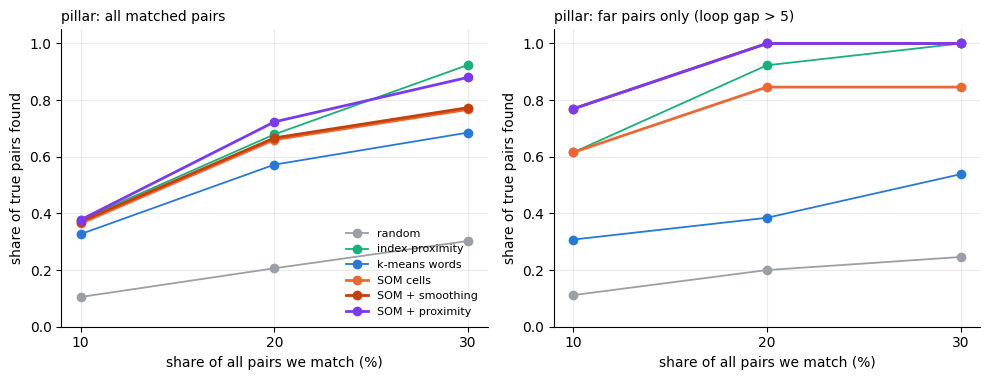

In [ ]:
# SOM add-on experiment (set RUN_SOM = False in the first code cell to skip)
if RUN_SOM:
    #can a SOM choose which image pairs to match? (uses Stage 3 features + Stage 4 results, no re-matching)
    import os, warnings, numpy as np, pandas as pd, cv2
    import matplotlib.pyplot as plt
    warnings.filterwarnings("ignore", category=RuntimeWarning)     # "mean of empty slice" when a scene has no far pairs
    from scipy.sparse import coo_matrix, csr_matrix
    from scipy.sparse.csgraph import connected_components
    from scipy.stats import rankdata


    GRID         = 12                 # SOM has GRID x GRID cells; k-means gets the same number of visual words
    EPOCHS       = 25
    SAMPLE_DESC  = 60000              # descriptors used to train both codebooks
    BUDGETS      = [0.1, 0.2, 0.3]    # share of all pairs we allow ourselves to match
    RANDOM_DRAWS = 20                 # random baseline is averaged over this many draws
    FAR          = globals().get("FAR_LOOP", 5)    # "far" = further apart than this around the loop
    OUT5         = "/content/som_addon"

    os.makedirs(OUT5, exist_ok=True)
    cv2.setRNGSeed(0)
    cells = GRID * GRID
    gy, gx = np.divmod(np.arange(cells), GRID)
    D2 = (gy[:, None] - gy[None]) ** 2 + (gx[:, None] - gx[None]) ** 2          # squared distance between map cells
    METHODS = ["random", "index proximity", "k-means words", "SOM cells", "SOM + smoothing", "SOM + proximity"]
    COLORS  = dict(zip(METHODS, ["#9aa0a6", "#1baf7a", "#2a78d6", "#eb6834", "#c2410c", "#7c3aed"]))

    def train_som(X, rng, epochs=EPOCHS):
        W = X[rng.choice(len(X), cells, replace=False)].copy()
        for e in range(epochs):
            sigma = max(GRID / 2 * (1 - e / epochs), 0.7) # neighbourhood shrinks over time
            bmu = ((W ** 2).sum(1)[None] - 2 * X @ W.T).argmin(1)  # best matching cell per descriptor
            oh = np.zeros((len(X), cells), np.float32); oh[np.arange(len(X)), bmu] = 1
            H = np.exp(-D2 / (2 * sigma ** 2))
            num, den = H @ (oh.T @ X), H @ oh.sum(0)
            W = np.where(den[:, None] > 1e-9, num / np.maximum(den[:, None], 1e-9), W)
        return W

    def signatures(W, desc, smooth=0.0):
        n = len(desc); hist = np.zeros((n, cells))
        for i, d in enumerate(desc):
            bmu = ((W ** 2).sum(1)[None] - 2 * d @ W.T).argmin(1)
            hist[i] = np.bincount(bmu, minlength=cells) / len(d)
        if smooth > 0: # spread counts to neighbouring map cells
            Hs = np.exp(-D2 / (2 * smooth ** 2)); Hs /= Hs.sum(1, keepdims=True); hist = hist @ Hs
        idf = np.log(n / (1 + (hist > 0).sum(0))); sig = hist * idf
        return sig / (np.linalg.norm(sig, axis=1, keepdims=True) + 1e-9)

    def n_tracks3(M, nkp):
        """tracks seen in >= 3 views, built from the verified matches M (same rule as Stage 4)"""
        if not M: return 0
        offs = np.concatenate([[0], np.cumsum(nkp)])
        ea = np.concatenate([offs[i] + m[:, 0] for (i, j), m in M.items()]); eb = np.concatenate([offs[j] + m[:, 1] for (i, j), m in M.items()])
        N = int(offs[-1])
        _, lab = connected_components(coo_matrix((np.ones(len(ea)), (ea, eb)), shape=(N, N)), directed=False)
        used = np.unique(np.concatenate([ea, eb])); img = np.searchsorted(offs, used, side="right") - 1; lab_u = lab[used]
        o = np.lexsort((img, lab_u)); lab_s, img_s = lab_u[o], img[o]
        bad = np.unique(lab_s[1:][(lab_s[1:] == lab_s[:-1]) & (img_s[1:] == img_s[:-1])])
        keep = ~np.isin(lab_s, bad)
        return int((np.unique(lab_s[keep], return_counts=True)[1] >= 3).sum())

    res_rows, sim_rows, curves = [], [], {}
    for tag, S in stage2.items():
        names = S["names"]; n = len(names)
        desc = [features[tag][nm]["desc"].astype(np.float32) for nm in names]; nkp = [len(d) for d in desc]
        Wm = graph[tag]["inliers"]; iu = np.triu_indices(n, 1); P = len(iu[0])
        T = (Wm > 0)[iu]; lgap = loopgap(iu[1] - iu[0], n); far = lgap > FAR
        nb = (iu[1] - iu[0]) == 1 # neighbours are always matched (cheap)
        rng = np.random.default_rng(0)
        allD = np.vstack(desc); X = allD[rng.choice(len(allD), min(SAMPLE_DESC, len(allD)), replace=False)]
        W_som = train_som(X, rng)
        _, _, W_km = cv2.kmeans(X, cells, None, (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 25, 1e-3), 1, cv2.KMEANS_PP_CENTERS)
        sim = lambda sg: (sg @ sg.T)[iu]
        prox = -lgap.astype(float)
        sc = {"index proximity": prox, "k-means words": sim(signatures(W_km, desc)), "SOM cells": sim(signatures(W_som, desc)),
              "SOM + smoothing": sim(signatures(W_som, desc, smooth=1.0))}
        sc["SOM + proximity"] = rankdata(sc["SOM cells"]) + rankdata(prox)      # rank average of SOM similarity and capture order
        print(f"\n{tag}: {n} images, {P} pairs | truly matched (after 4b): {int(T.sum())} | far truly matched: {int((T & far).sum())}")

        def recall(s, mask, frac):
            t = T[mask]
            if t.sum() == 0: return np.nan
            take = np.argsort(-s[mask], kind="stable")[:max(1, int(round(frac * mask.sum())))]
            return t[take].sum() / t.sum()
        def auc(s, mask):
            t = T[mask]; pos = t.sum(); neg = len(t) - pos
            if pos == 0 or neg == 0: return np.nan
            return (rankdata(s[mask])[t].sum() - pos * (pos + 1) / 2) / (pos * neg)
        allm = np.ones(P, bool)
        for m in METHODS:
            for name, mask in (("all", allm), ("far", far)):
                if m == "random":
                    vals = [recall(np.random.default_rng(k).random(P), mask, f) for f in BUDGETS for k in range(RANDOM_DRAWS)]
                    rec = np.nanmean(np.array(vals).reshape(len(BUDGETS), RANDOM_DRAWS), axis=1); a = 0.5
                else:
                    rec = [recall(sc[m], mask, f) for f in BUDGETS]; a = auc(sc[m], mask)
                res_rows.append(dict(scene=tag, pairs=name, method=m, **{f"recall@{int(f*100)}%": r for f, r in zip(BUDGETS, rec)}, AUC=a))
                curves[(tag, name, m)] = rec
        # where does each method rank the first/last image pair (the loop closure)?
        ci = np.where((iu[0] == 0) & (iu[1] == n - 1))[0][0]
        print("   rank of the loop-closure pair (first, last image) among", P, "pairs:",
              {m: int(1 + (sc[m] > sc[m][ci]).sum()) for m in sc})

        #simulation: what if only the chosen pairs had been matched? (uses the Stage 4 results)
        pid = {(int(a), int(b)): k for k, (a, b) in enumerate(zip(*iu))}
        accepted = list(matches[tag].keys()); acc_idx = np.array([pid[k] for k in accepted])
        far_acc = np.array([far[k] for k in acc_idx])
        full_tr = n_tracks3(matches[tag], nkp)
        for f in BUDGETS:
            K = int(round(f * P))
            for m in METHODS:
                draws = range(RANDOM_DRAWS) if m == "random" else [0]
                out = []
                for k in draws:
                    s = np.random.default_rng(k).random(P) if m == "random" else sc[m]
                    sel = nb.copy(); sel[np.argsort(-s, kind="stable")[:K]] = True
                    keepk = [kk for kk, ix in zip(accepted, acc_idx) if sel[ix]]
                    Mr = {kk: matches[tag][kk] for kk in keepk}
                    A = np.zeros((n, n), bool)
                    for (a, b) in keepk: A[a, b] = A[b, a] = True
                    nc, _ = connected_components(csr_matrix(A), directed=False)
                    out.append((sel.mean(), len(keepk) / len(accepted), sel[acc_idx][far_acc].mean() if far_acc.any() else np.nan,
                                nc, A.sum(1).min(), n_tracks3(Mr, nkp) / max(full_tr, 1)))
                o = np.nanmean(np.array(out, float), axis=0)
                sim_rows.append(dict(scene=tag, budget=f"{int(f*100)}%", method=m, pairs_matched=round(o[0], 2), accepted_pairs_found=round(o[1], 2),
                                     far_pairs_found=round(o[2], 2), graph_parts=round(o[3], 1), min_partners=round(o[4], 1), tracks3_kept=round(o[5], 2)))

    res = pd.DataFrame(res_rows); sim_df = pd.DataFrame(sim_rows)
    res.round(2).to_csv(f"{OUT5}/som_ranking.csv", index=False); sim_df.to_csv(f"{OUT5}/som_simulation.csv", index=False)
    pd.set_option("display.width", 200)
    for tag in stage2:
        print(f"\n=== {tag}: how well does each method rank the truly matched pairs? (recall = share found inside the top x% of pairs) ===")
        print(res[res.scene == tag].drop(columns="scene").round(2).to_string(index=False))
        print(f"\n=== {tag}: simulated pair selection (neighbours always matched + top x% by score) ===")
        print(sim_df[sim_df.scene == tag].drop(columns="scene").to_string(index=False))

    #chart: recall vs matching budget, all pairs and far pairs, one row per scene
    fig, axes = plt.subplots(len(stage2), 2, figsize=(10, 3.9 * len(stage2)), squeeze=False, sharex=True)
    for row, tag in zip(axes, stage2):
        for ax, name in zip(row, ("all", "far")):
            for m in METHODS:
                ax.plot([int(f * 100) for f in BUDGETS], curves[(tag, name, m)], marker="o", color=COLORS[m], lw=2 if "SOM" in m else 1.3,
                        label=m)
            ax.set_title(f"{tag}: {'all matched pairs' if name == 'all' else f'far pairs only (loop gap > {FAR})'}", fontsize=10, loc="left")
            ax.set_xlabel("share of all pairs we match (%)"); ax.set_ylabel("share of true pairs found"); ax.set_ylim(0, 1.05)
            ax.grid(alpha=0.25); ax.set_xticks([int(f * 100) for f in BUDGETS])
            for s in ("top", "right"): ax.spines[s].set_visible(False)
    axes[0][0].legend(frameon=False, fontsize=8, loc="lower right")
    plt.tight_layout(); plt.show()
    shutil.rmtree(f"{PROJECT}/som_addon", ignore_errors=True); shutil.copytree(OUT5, f"{PROJECT}/som_addon")   # saved to Drive

### Stages 5-6
Input: the saved Stage 3/4 results (`SfM_backup` on Drive). Output: sparse model (camera poses + 3D points).

Setup

In [ ]:
# Stages 5-6 setup: saved Stage 3/4 results + helpers
import os, glob, json, time, shutil, numpy as np, pandas as pd, cv2, matplotlib.pyplot as plt

SRC, OUT = SB, "/content/stage6_output"# SB = saved Stage 3-4 results (set by the load / save cells above)

base = dict(e_px=1.0, min_pts=100, min_ang=3.0, pnp_px=4.0, min_inl=25, min_ratio=0.25, tries=3,
            err_px=4.0, tri_ang=1.5, rot_tol=15.0, flat=0.05, near=5)   # near: photos taken in order round the tower
tune = {t: {} for t in SCENES.values()}
refine = None  # optional hook: refine(m, i) / refine(m, None)

def use(s):
    global cfg
    cfg = {**base, **tune.get(s, {})}
use(next(iter(SCENES.values())))

c = globals().get("CAMERA", dict(fx=1126.75, fy=1126.75, cx=600.0, cy=800.0))
K = np.array([[c["fx"], 0, c["cx"]], [0, c["fy"], c["cy"]], [0, 0, 1.0]])

data = {}
for s in sorted(os.listdir(f"{SRC}/stage4_matches")):
    d3, d4 = f"{SRC}/stage3_features/{s}", f"{SRC}/stage4_matches/{s}"
    if not os.path.isfile(f"{d4}/tracks.npz"):
        continue
    nm = open(f"{d4}/image_names.txt").read().splitlines()
    m, t = np.load(f"{d4}/matches.npz"), np.load(f"{d4}/tracks.npz")
    data[s] = dict(names=nm, K=K, ptr=t["ptr"], img=t["img"], kp=t["kp"],
                   pts=[np.load(f"{d3}/{n}.npz")["pts"].astype(float) for n in nm],
                   pairs={tuple(map(int, k.split("_"))): m[k] for k in m.files},
                   start=pd.read_csv(f"{d4}/start_pairs.csv"), color=f"/content/stage2_output/{s}/color")
    print(f"{s}: {len(nm)} images, {len(m.files)} pairs, {len(t['ptr']) - 1} tracks")

def angle(R):
    return np.degrees(np.arccos(np.clip((np.trace(R) - 1) / 2, -1, 1)))

def tri(P, x):   # DLT: P (m,v,3,4), x (m,v,2) -> X (m,3)
    A = np.concatenate([x[..., :1] * P[..., 2, :] - P[..., 0, :], x[..., 1:] * P[..., 2, :] - P[..., 1, :]], 1)
    A /= np.linalg.norm(A, axis=2, keepdims=True) + 1e-12
    h = np.linalg.svd(A)[2][:, -1]
    with np.errstate(all="ignore"):
        return h[:, :3] / h[:, 3:]

def ray_ang(C, X):    # widest angle between the rays to X (deg)
    d = X[:, None] - C
    d /= np.linalg.norm(d, axis=2, keepdims=True) + 1e-12
    return np.degrees(np.arccos(np.clip(np.einsum("mvk,mwk->mvw", d, d).min((1, 2)), -1, 1)))

def groups(o, tr):   # observations grouped by track length
    u, f, n = np.unique(tr[o], return_index=True, return_counts=True)
    for v in np.unique(n):
        yield u[n == v], o[f[n == v][:, None] + np.arange(v)]

pillar: 35 images, 159 pairs, 9605 tracks


Engine

In [ ]:
# Stage 5-6 engine: one 3D point per Stage 4 track (bundle adjustment is added through the refine hook, Stage 7)
class SfM:
    def __init__(self, s):
        d = data[s]
        self.names, self.K, self.pairs, self.pts = d["names"], d["K"], d["pairs"], d["pts"]
        self.n, self.nt = len(self.names), len(d["ptr"]) - 1
        self.tr = np.repeat(np.arange(self.nt), np.diff(d["ptr"]))   # per observation: track, image, keypoint
        self.im, self.kp = d["img"].astype(int), d["kp"].astype(int)
        self.xy = np.array([self.pts[i][k] for i, k in zip(self.im, self.kp)])
        self.xn = (np.c_[self.xy, np.ones(len(self.xy))] @ np.linalg.inv(self.K).T)[:, :2]
        self.obs = [np.full(len(p), -1) for p in self.pts]
        for o, (i, k) in enumerate(zip(self.im, self.kp)):
            self.obs[i][k] = o
        self.reg, self.order, self.fails, self.log = np.zeros(self.n, bool), [], {}, []
        self.R, self.t = np.tile(np.eye(3), (self.n, 1, 1)), np.zeros((self.n, 3))
        self.X, self.has = np.full((self.nt, 3), np.nan), np.zeros(self.nt, bool)
        self.used = np.zeros(len(self.im), bool)
        self.loop = LOOP_FLAGS.get(s, True) # closed ring of photos, or open arc

    def centers(self, i=slice(None)):
        return -np.einsum("nji,nj->ni", self.R[i], self.t[i])

    def errors(self, o):
        Xc = np.einsum("nij,nj->ni", self.R[self.im[o]], self.X[self.tr[o]]) + self.t[self.im[o]]
        with np.errstate(all="ignore"):
            e = np.linalg.norm(Xc[:, :2] / Xc[:, 2:] @ self.K[:2, :2].T + self.K[:2, 2] - self.xy[o], axis=1)
        return np.nan_to_num(e, nan=np.inf), Xc[:, 2]

    def stats(self):
        e, _ = self.errors(np.where(self.used)[0])
        return dict(cams=int(self.reg.sum()), points=int(self.has.sum()), obs=int(self.used.sum()),
                    err=round(float(e.mean()), 3), median_err=round(float(np.median(e)), 3))

    def _tri(self, o):
        ok_, retry, P, C = [], [], np.concatenate([self.R, self.t[:, :, None]], 2), self.centers()
        for T, O in groups(o, self.tr):
            if O.shape[1] < 2:
                continue
            X = tri(P[self.im[O]], self.xn[O])
            Xc = np.einsum("mvij,mj->mvi", self.R[self.im[O]], np.nan_to_num(X)) + self.t[self.im[O]]
            with np.errstate(all="ignore"):
                e = np.linalg.norm(Xc[..., :2] / Xc[..., 2:] @ self.K[:2, :2].T + self.K[:2, 2] - self.xy[O], axis=2)
            ok = (Xc[..., 2] > 0) & (e < cfg["err_px"]) & np.isfinite(X).all(1)[:, None]
            wide = ray_ang(C[self.im[O]], np.nan_to_num(X)) >= cfg["tri_ang"]
            ok_ += [(T[k], X[k], O[k]) for k in np.where(ok.all(1) & wide)[0]]
            retry += [O[k][ok[k]] for k in np.where(~ok.all(1) & (ok.sum(1) >= 2))[0]]
        return ok_, retry

    def grow(self, tracks=None):  # new points from placed views
        want = ~self.has if tracks is None else np.isin(np.arange(self.nt), tracks) & ~self.has
        ok, retry = self._tri(np.where(want[self.tr] & self.reg[self.im])[0])
        if retry:
            ok += self._tri(np.sort(np.concatenate(retry)))[0]
        for T, X, O in ok:
            self.X[T], self.has[T], self.used[O] = X, True, True
        return len(ok)

    def retri(self, tracks):  # existing points from all their views
        P = np.concatenate([self.R, self.t[:, :, None]], 2)
        for T, O in groups(np.where(self.used & np.isin(self.tr, tracks) & self.has[self.tr])[0], self.tr):
            if O.shape[1] < 3:
                continue
            old = self.X[T].copy()
            e0 = self.errors(O.ravel())[0].reshape(O.shape).max(1)
            self.X[T] = tri(P[self.im[O]], self.xn[O])
            e1, z = self.errors(O.ravel())
            bad = ~((e1.reshape(O.shape).max(1) <= e0) & (z.reshape(O.shape) > 0).all(1))
            self.X[T[bad]] = old[bad]

    def extend(self): # reusing observations that now fit
        o = np.where(self.has[self.tr] & self.reg[self.im] & ~self.used)[0]
        e, z = self.errors(o)
        self.used[o[(e < cfg["err_px"]) & (z > 0)]] = True

    def clean(self): # outlier check
        o = np.where(self.used)[0]
        e, z = self.errors(o)
        self.used[o[(e > cfg["err_px"]) | (z <= 0)]] = False
        drop = self.has & (np.bincount(self.tr[self.used], minlength=self.nt) < 2)
        C = self.centers()
        for T, O in groups(np.where(self.used & ~drop[self.tr])[0], self.tr):
            drop[T[ray_ang(C[self.im[O]], self.X[T]) < cfg["tri_ang"]]] = True
        self.has[drop], self.X[drop], self.used[drop[self.tr]] = False, np.nan, False

    #Stage 5
    def pair(self, i, j):# two-view pose + checks
        m = self.pairs.get((i, j))
        if m is None or len(m) < 8:
            return None
        a, b = self.pts[i][m[:, 0]], self.pts[j][m[:, 1]]
        cv2.setRNGSeed(0)
        E, inl = cv2.findEssentialMat(a, b, self.K, cv2.RANSAC, 0.999, cfg["e_px"])
        if E is None:
            return None
        inl = inl.ravel() > 0
        Ki = np.linalg.inv(self.K)
        xa, xb = [(np.c_[p, np.ones(len(p))] @ Ki.T)[inl, :2] for p in (a, b)]
        W, best = np.array([[0, -1, 0], [1, 0, 0], [0, 0, 1.0]]), None
        for E1 in E.reshape(-1, 3, 3):                                   # 4 poses: keep the one with points in front
            U, _, Vt = np.linalg.svd(E1)
            U, Vt = U * np.sign(np.linalg.det(U)), Vt * np.sign(np.linalg.det(Vt))
            for R, t in [(U @ W @ Vt, U[:, 2]), (U @ W @ Vt, -U[:, 2]), (U @ W.T @ Vt, U[:, 2]), (U @ W.T @ Vt, -U[:, 2])]:
                P = np.stack([np.c_[np.eye(3), np.zeros(3)], np.c_[R, t]])
                X = tri(np.broadcast_to(P, (len(xa), 2, 3, 4)), np.stack([xa, xb], 1))
                f = np.isfinite(X).all(1) & (X[:, 2] > 0) & ((X @ R.T + t)[:, 2] > 0)
                if best is None or f.sum() > best[3].sum():
                    best = (R, t, X, f)
        R, t, X, f = best
        X = np.nan_to_num(X)
        with np.errstate(all="ignore"):
            e = np.maximum(np.linalg.norm(X[:, :2] / X[:, 2:] - xa, axis=1),
                           np.linalg.norm((X @ R.T + t)[:, :2] / (X @ R.T + t)[:, 2:] - xb, axis=1)) * self.K[0, 0]
        a = ray_ang(np.broadcast_to(np.stack([np.zeros(3), -R.T @ t]), (len(X), 2, 3)), X)
        g = f & (e < cfg["err_px"]) & (a >= cfg["tri_ang"])
        md = float(np.median(a[g])) if g.any() else 0.0
        return dict(i=i, j=j, R=R, t=t, matches=len(m), inliers=int(inl.sum()), good=int(g.sum()), angle=round(md, 2),
                    score=g.sum() * min(1, md / 8), ok=bool(g.sum() >= cfg["min_pts"] and md >= cfg["min_ang"]))

    def start(self, c):
        r = [x for x in (self.pair(i, j) for i, j in c) if x]
        b = max([x for x in r if x["ok"]] or r, key=lambda x: x["score"])
        i, j = b["i"], b["j"]
        self.R[j], self.t[j] = b["R"], b["t"] / np.linalg.norm(b["t"])  # baseline = 1 sets the scale
        self.reg[[i, j]], self.order = True, [i, j]
        self.grow()
        self.clean()
        self.first = dict(pair=(self.names[i], self.names[j]), matches=b["matches"], inliers=b["inliers"], angle=b["angle"])
        for k in (i, j):
            self.log.append(dict(image=self.names[k], status="start", **self.stats()))
        T = pd.DataFrame([{k: v for k, v in x.items() if k not in "Rt"} for x in r])
        T["i"], T["j"] = [self.names[x] for x in T.i], [self.names[x] for x in T.j]
        return T.sort_values("score", ascending=False)

    # Stage 6
    def seen(self, i):
        o = self.obs[i][self.obs[i] >= 0]
        return o[self.has[self.tr[o]]]

    def gap(self, i, j):  # distance in capture order (loop)
        return min(abs(i - j), self.n - abs(i - j)) if self.loop else abs(i - j)

    def pick(self): # next photo: sees most points, near a placed one
        best, most = None, 0
        for i in np.where(~self.reg)[0]:
            if not any(self.reg[j] and self.gap(i, j) <= cfg["near"] for j in range(self.n)):
                continue
            n, (f, last) = len(self.seen(i)), self.fails.get(i, (0, 0))
            if f < cfg["tries"] and n > last * 1.2 and n > most:
                best, most = i, n
        return best

    def nbrs(self, i, k=3): # placed nearby photos best matched to i
        nb = sorted(((len(m), b if a == i else a) for (a, b), m in self.pairs.items()
                     if i in (a, b) and self.reg[b if a == i else a] and self.gap(a, b) <= cfg["near"]), reverse=True)
        return [j for _, j in nb[:k]]

    def pred_R(self, i): # i's rotation from its own two-view pairs
        out = []
        for j in self.nbrs(i, 2):
            v = self.pair(min(i, j), max(i, j))
            if v and v["good"] >= 15:
                out.append(v["R"].T @ self.R[j] if i < j else v["R"] @ self.R[j])
        return out

    def add(self, i):
        o = self.seen(i)
        row = dict(image=self.names[i], corr=len(o), inliers=0, rot_check=np.nan, flat=False, new=0)
        def fail(why):
            self.fails[i] = (self.fails.get(i, (0, 0))[0] + 1, len(o))
            self.log.append(dict(row, status="failed: " + why, **self.stats()))
            return False
        if len(o) < 30:
            return fail("too few 2D-3D matches")
        X3, x2, Rp = self.X[self.tr[o]], self.xy[o], self.pred_R(i)
        def off(R):
            return float(np.median([angle(R @ q.T) for q in Rp])) if Rp else 0.0
        def fit(R, t):
            Xc = X3 @ R.T + t
            with np.errstate(all="ignore"):
                return ((np.linalg.norm(Xc[:, :2] / Xc[:, 2:] @ self.K[:2, :2].T + self.K[:2, 2] - x2, axis=1)
                         < cfg["pnp_px"]) & (Xc[:, 2] > 0)).sum()
        # tries: all matches -> points the neighbours see -> all minus a rejected pose (look-alike tower sides)
        near = np.isin(self.tr[o], self.tr[self.used & np.isin(self.im, self.nbrs(i))])
        tries, why = [np.arange(len(o)), np.where(near)[0]], "PnP"
        for k, sub in enumerate(tries):
            if len(sub) < cfg["min_inl"]:
                continue
            cv2.setRNGSeed(0)
            ok, r, t, inl = cv2.solvePnPRansac(X3[sub], x2[sub], self.K, None, iterationsCount=3000,
                                               reprojectionError=cfg["pnp_px"], confidence=0.9999, flags=cv2.SOLVEPNP_AP3P)
            if not ok or len(inl) < cfg["min_inl"] or len(inl) < cfg["min_ratio"] * len(sub):
                continue
            inl = sub[inl.ravel()]
            poses = [cv2.solvePnPRefineLM(X3[inl], x2[inl], self.K, None, r, t)]
            sv = np.linalg.svd(X3[inl] - X3[inl].mean(0), compute_uv=False)
            row["flat"] = bool(sv[2] < cfg["flat"] * sv[0])
            if row["flat"]:  # flat wall: two poses fit, try both
                _, rs, ts, _ = cv2.solvePnPGeneric(X3[inl], x2[inl], self.K, None, flags=cv2.SOLVEPNP_IPPE)
                poses += [cv2.solvePnPRefineLM(X3[inl], x2[inl], self.K, None, u, v) for u, v in zip(rs, ts)]
            poses = [(cv2.Rodrigues(u)[0], v.ravel()) for u, v in poses]
            n = [fit(*q) for q in poses]
            R, t = min((q for q, c in zip(poses, n) if c >= 0.9 * max(n)), key=lambda q: off(q[0]))
            row["inliers"], row["rot_check"] = len(inl), round(off(R), 2)
            if row["rot_check"] <= cfg["rot_tol"]:
                break
            why = "pose disagrees with two-view geometry"
            if k == 0:
                tries.append(np.setdiff1d(sub, inl))
        else:
            return fail(why)
        self.R[i], self.t[i], self.reg[i] = R, t, True
        self.order.append(i)
        e, z = self.errors(o)
        self.used[o] = (e < cfg["err_px"]) & (z > 0)
        own = self.tr[self.obs[i][self.obs[i] >= 0]]
        self.retri(own)
        row["new"] = self.grow(own)
        self.log.append(dict(row, status="added", **self.stats()))
        return True

    def upright(self): # ring centred, flat, radius 1; tower up (+y)
        k = np.where(self.reg)[0]
        C = self.centers(k)
        mu = C.mean(0)
        up = np.linalg.svd(C - mu)[2][2]
        up *= np.sign(up @ -self.R[k, 1].sum(0))
        x = C[0] - mu - (C[0] - mu) @ up * up
        x /= np.linalg.norm(x)
        W = np.stack([x, up, np.cross(x, up)])
        sc = 1 / np.linalg.norm((C - mu) - np.outer((C - mu) @ up, up), axis=1).mean()
        self.t = sc * (self.t + self.R @ mu)
        self.R = self.R @ W.T
        self.X = sc * (self.X - mu) @ W.T

    def run(self, say=print):
        while (i := self.pick()) is not None:
            if not self.add(i):
                say(f"   x {self.names[i]}: {self.log[-1]['status']}")
                continue
            if refine:
                refine(self, i)
            self.clean()
            L = self.log[-1]
            say(f"   + {L['image']}: {L['corr']} 2D-3D, {L['inliers']} inliers, rot {L['rot_check']:.1f} deg"
                f"{' (flat)' if L['flat'] else ''}, +{L['new']} pts | {self.reg.sum()} cams, {self.has.sum()} pts")
        self.extend()
        self.grow()
        self.clean()
        if refine:
            refine(self, None)
            self.clean()
        self.upright()
        return self

Stage 5: initialisation


pillar: start ('pillar_33', 'pillar_34'), 797/803 inliers, angle 11.68 deg -> {'cams': 2, 'points': 839, 'obs': 1678, 'err': 0.135, 'median_err': 0.091}
        i         j  matches  inliers  good  angle  score   ok
pillar_33 pillar_34      803      797   792  11.68 792.00 True
pillar_34 pillar_35      787      765   763   7.06 673.18 True
pillar_32 pillar_33      721      642   640  10.60 640.00 True
pillar_03 pillar_04      652      619   617  12.87 617.00 True
pillar_04 pillar_05      539      527   527   7.95 523.61 True


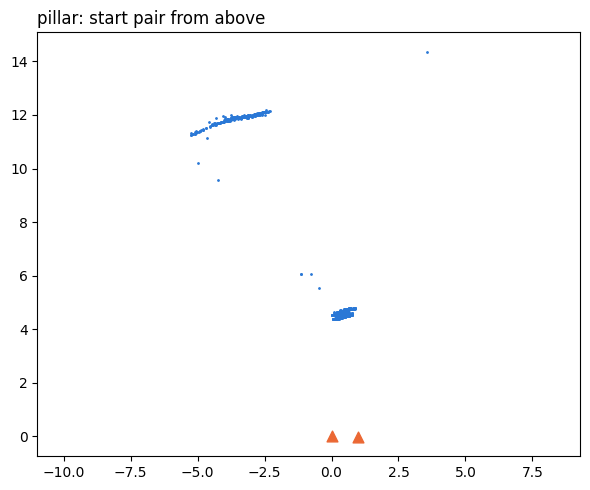

In [ ]:
# Stage 5: best starting pair -> first two-view model
def cand(s):# Stage 4's top 10 pairs (+ neighbours if few)
    d = data[s]
    c = [(d["names"].index(a), d["names"].index(b)) for a, b in zip(d["start"].img_i, d["start"].img_j)][:10]
    if len(c) < 3:
        c += [k for k in sorted(d["pairs"], key=lambda k: -len(d["pairs"][k])) if 2 <= k[1] - k[0] <= 6][:10]
    return c

M, st = {}, {}
for s in data:
    use(s)
    m = M[s] = SfM(s)
    st[s] = m.start(cand(s))
    f = m.first
    print(f"\n{s}: start {f['pair']}, {f['inliers']}/{f['matches']} inliers, angle {f['angle']} deg -> {m.stats()}")
    print(st[s].round(2).head(5).to_string(index=False))

fig, ax = plt.subplots(1, len(M), figsize=(6 * len(M), 5), squeeze=False)
for a, (s, m) in zip(ax[0], M.items()):
    X, C = m.X[m.has], m.centers(m.order)
    lo, hi = np.percentile(X, [2, 98], 0)
    X = X[((X > lo) & (X < hi)).all(1)]
    a.scatter(X[:, 0], X[:, 2], s=1, c="#2a78d6")
    a.scatter(C[:, 0], C[:, 2], s=60, c="#eb6834", marker="^")
    a.set_title(f"{s}: start pair from above", loc="left"); a.set_aspect("equal", "datalim")
plt.tight_layout(); plt.show()

Stage 6: incremental expansion

In [ ]:
# Stage 6: add the other photos one by one (pick -> PnP + checks -> points -> outlier check), then upright
for s, m in M.items():
    use(s)
    print(f"\n{s}:")
    t0 = time.time()
    m.run()
    left = [m.names[i] for i in np.where(~m.reg)[0]]
    print(f"   done in {time.time() - t0:.0f}s -> {m.stats()}" + (f" | not added: {left}" if left else ""))


pillar:
   + pillar_35: 482 2D-3D, 476 inliers, rot 0.8 deg, +533 pts | 3 cams, 1372 pts
   + pillar_01: 760 2D-3D, 748 inliers, rot 1.0 deg, +261 pts | 4 cams, 1633 pts
   + pillar_02: 675 2D-3D, 600 inliers, rot 0.9 deg (flat), +412 pts | 5 cams, 2045 pts
   + pillar_03: 730 2D-3D, 633 inliers, rot 1.7 deg, +380 pts | 6 cams, 2425 pts
   + pillar_32: 852 2D-3D, 737 inliers, rot 1.0 deg, +286 pts | 7 cams, 2711 pts
   + pillar_04: 851 2D-3D, 745 inliers, rot 0.8 deg, +206 pts | 8 cams, 2917 pts
   + pillar_31: 672 2D-3D, 458 inliers, rot 1.2 deg, +248 pts | 9 cams, 3165 pts
   + pillar_05: 565 2D-3D, 476 inliers, rot 0.4 deg, +193 pts | 10 cams, 3358 pts
   + pillar_30: 372 2D-3D, 182 inliers, rot 0.3 deg, +209 pts | 11 cams, 3567 pts
   + pillar_06: 191 2D-3D, 127 inliers, rot 0.3 deg, +152 pts | 12 cams, 3719 pts
   + pillar_29: 165 2D-3D, 100 inliers, rot 2.2 deg, +168 pts | 13 cams, 3887 pts
   + pillar_28: 143 2D-3D, 120 inliers, rot 0.8 deg, +222 pts | 14 cams, 4109 pts
   + pi

Stage 6 check: failures and drift


pillar: 33 added, 1 failed
   median rotation error (deg) by gap: {'1': 0.78, '2-5': 2.81, '6-10': 1.38}
   loop closure: 1.81 deg | off > 5 deg: 29 (near 180 = look-alike side)


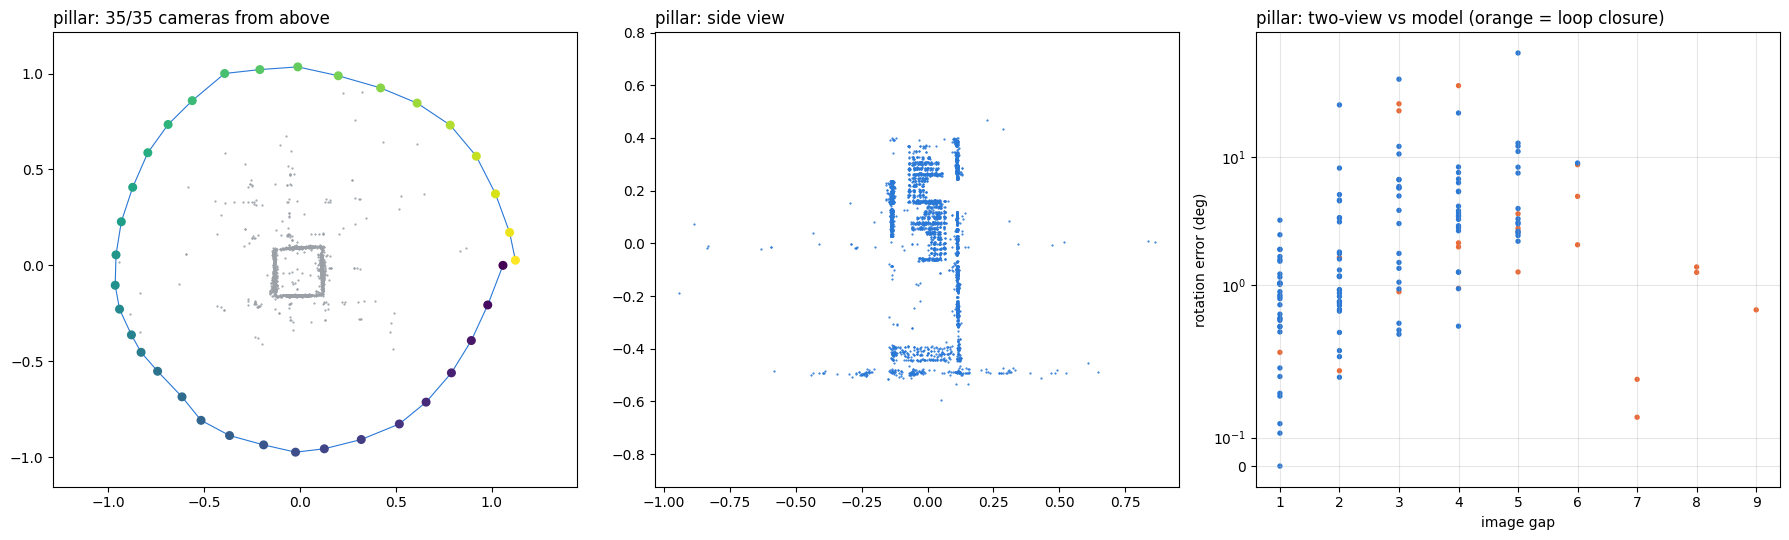

In [ ]:
# Stage 6 check: failures + drift (each pair's own rotation vs the model)
def pchk(m):
    r = []
    for i, j in m.pairs:
        v = m.pair(i, j) if m.reg[i] and m.reg[j] else None
        if v and v["good"] >= 15:
            r.append(dict(i=m.names[i], j=m.names[j], gap=m.gap(i, j), loop=(j - i > m.n / 2) if m.loop else False,
                          err=angle(v["R"].T @ m.R[j] @ m.R[i].T)))
    return pd.DataFrame(r)

chk = {}
fig, ax = plt.subplots(len(M), 3, figsize=(18, 5.5 * len(M)), squeeze=False)
for (a1, a2, a3), (s, m) in zip(ax, M.items()):
    use(s)
    L, c = pd.DataFrame(m.log), pchk(m)
    chk[s] = c
    print(f"\n{s}: {(L.status == 'added').sum()} added, {L.status.str.startswith('failed').sum()} failed")
    print("   median rotation error (deg) by gap:", c.groupby(pd.cut(c.gap, [0, 1, 5, 10, 20, 99],
          labels=["1", "2-5", "6-10", "11-20", ">20"]), observed=True).err.median().round(2).to_dict())
    print(f"   loop closure: {c[c.loop].err.median():.2f} deg | off > 5 deg: {(c.err > 5).sum()} (near 180 = look-alike side)")
    k = np.where(m.reg)[0]
    C, X = m.centers(k), m.X[m.has]
    X = X[np.linalg.norm(X[:, [0, 2]], axis=1) < 1]
    a1.scatter(X[:, 0], X[:, 2], s=0.3, c="#9aa0a6")
    a1.plot(C[:, 0], C[:, 2], c="#2a78d6", lw=0.8)
    a1.scatter(C[:, 0], C[:, 2], c=k, s=30, zorder=3)
    a1.set_title(f"{s}: {len(k)}/{m.n} cameras from above", loc="left"); a1.set_aspect("equal", "datalim")
    a2.scatter(X[:, 0], X[:, 1], s=0.3, c="#2a78d6")
    a2.set_title(f"{s}: side view", loc="left"); a2.set_aspect("equal", "datalim")
    a3.scatter(c.gap, c.err, s=8, c=np.where(c.loop, "#eb6834", "#2a78d6"))
    a3.set_yscale("symlog", linthresh=0.5); a3.grid(alpha=0.3)
    a3.set_xlabel("image gap"); a3.set_ylabel("rotation error (deg)")
    a3.set_title(f"{s}: two-view vs model (orange = loop closure)", loc="left")
plt.tight_layout(); plt.show()

Phase 7: parameter tests

In [ ]:
# Phase 7: parameter tests per scene (~15 min; TESTS = False skips)
TESTS = False
var = [("used settings", {}), ("pnp_px 2", {"pnp_px": 2.0}), ("pnp_px 8", {"pnp_px": 8.0}),
        ("tri_ang 0.5", {"tri_ang": 0.5}), ("tri_ang 3", {"tri_ang": 3.0}), ("no order check", {"near": 999})]
r = []
for s in data if TESTS else []:
    for name, ch in var:
        m = M[s]
        if ch:
            keep, tune[s] = tune.get(s, {}), {**tune.get(s, {}), **ch}
            use(s)
            m = SfM(s)
            m.start(cand(s))
            m.run(say=lambda *a: None)
            tune[s] = keep
        use(s)
        c = pchk(m)
        r.append(dict(scene=s, test=name, **m.stats(), loop_err=round(c[c.loop].err.median(), 2),
                      off_5deg=int((c.err > 5).sum()), failed=sum(L["status"].startswith("failed") for L in m.log)))
        print(r[-1])
tt = pd.DataFrame(r)

### Stage 7: bundle adjustment
Joint refinement of camera poses and 3D points by minimising pixel reprojection error (`scipy.optimize.least_squares`, sparse Jacobian, Huber loss).
It plugs into the engine through the `refine` hook: a **local BA** after every new photo (newest 4 cameras + the points they see), then a **global BA** at the end, then outlier removal, then a second global BA that also refines one shared focal length (calibration was provisional).
Camera 0 is fixed to remove the gauge freedom; scale is free and normalised afterwards by `upright()`.

In [ ]:
# Stage 7A: bundle adjustment + refine hook
from scipy.optimize import least_squares
from scipy.sparse import coo_matrix
from scipy.spatial.transform import Rotation as Rot

REFINE_F     = True   # final global BA also refines one shared focal length
BA_LOCAL_K   = 4      # after each new photo: re-optimise the newest K cameras + the points they see
BA_LOCAL_IT  = 10     # max function evaluations for a local BA
BA_GLOBAL_IT = 300    # max function evaluations for a global BA (100 was not enough to converge)
HUBER_PX     = 2.0    # Huber threshold in pixels (outliers get a linear, not squared, cost)
ba_log = []           # one dict per BA call (goes into ba_log.csv)


def ba(m, free=None, refine_f=False, max_nfev=50, verbose=0, tag=""):
    """free=None -> global BA (all cameras except the first, which fixes the gauge).
    free=[...]  -> local BA (only these cameras move, plus the points they see; the rest is held fixed)."""
    o_all = np.where(m.used & m.has[m.tr] & m.reg[m.im])[0]
    cnt = np.bincount(m.tr[o_all], minlength=m.nt)
    cams_in = np.unique(m.im[o_all])
    gauge = m.order[0]
    local = free is not None
    free = np.array([c for c in cams_in if c != gauge]) if not local else np.intersect1d(free, cams_in)
    free = free[free != gauge]
    if len(free) == 0:
        return None
    good = (cnt >= 2) & m.has
    if local:
        seen = np.zeros(m.nt, bool)
        seen[m.tr[o_all[np.isin(m.im[o_all], free)]]] = True
        good &= seen
    pts = np.where(good)[0]
    o = o_all[good[m.tr[o_all]]]
    nf, npt, no = len(free), len(pts), len(o)
    cam_idx = np.full(m.n, -1); cam_idx[free] = np.arange(nf)
    pt_idx = np.full(m.nt, -1); pt_idx[pts] = np.arange(npt)
    ci, pi, cams = cam_idx[m.im[o]], pt_idx[m.tr[o]], m.im[o]
    fm = ci >= 0   # observation made by a moving camera
    c0 = m.K[:2, 2].copy()
    nparam = 6 * nf + 3 * npt + (1 if refine_f else 0)
    x0 = np.concatenate([Rot.from_matrix(m.R[free]).as_rotvec().ravel(), m.t[free].ravel(),
                         m.X[pts].ravel(), [m.K[0, 0]] if refine_f else []])

    def project(x):
        rv, tv = x[:3 * nf].reshape(nf, 3), x[3 * nf:6 * nf].reshape(nf, 3)
        P = x[6 * nf:6 * nf + 3 * npt].reshape(npt, 3)
        f = x[-1] if refine_f else m.K[0, 0]
        Xc = np.empty((no, 3))
        Xc[fm] = Rot.from_rotvec(rv[ci[fm]]).apply(P[pi[fm]]) + tv[ci[fm]]
        Xc[~fm] = np.einsum("nij,nj->ni", m.R[cams[~fm]], P[pi[~fm]]) + m.t[cams[~fm]]
        z = Xc[:, 2:]
        z = np.where(np.abs(z) < 1e-9, 1e-9, z)
        return Xc[:, :2] / z * f + c0

    def fun(x):
        return (project(x) - m.xy[o]).ravel()

    r = np.arange(no)  # Jacobian sparsity: layout = all rotvecs, all translations, points, [f]
    rows, cols = [], []
    for k in range(2):
        for c in range(3):
            rows.append((2 * r + k)[fm]); cols.append(3 * ci[fm] + c)
            rows.append((2 * r + k)[fm]); cols.append(3 * nf + 3 * ci[fm] + c)
            rows.append(2 * r + k);       cols.append(6 * nf + 3 * pi + c)
        if refine_f:
            rows.append(2 * r + k); cols.append(np.full(no, nparam - 1))
    rows, cols = np.concatenate(rows), np.concatenate(cols)
    A = coo_matrix((np.ones(len(rows), bool), (rows, cols)), shape=(2 * no, nparam)).tocsr()

    e0 = np.linalg.norm(fun(x0).reshape(-1, 2), axis=1)
    sol = least_squares(fun, x0, jac_sparsity=A, loss="huber", f_scale=HUBER_PX, x_scale="jac",
                        method="trf", max_nfev=max_nfev, verbose=verbose)
    x = sol.x
    e1 = np.linalg.norm(fun(x).reshape(-1, 2), axis=1)
    m.R[free] = Rot.from_rotvec(x[:3 * nf].reshape(nf, 3)).as_matrix()
    m.t[free] = x[3 * nf:6 * nf].reshape(nf, 3)
    m.X[pts] = x[6 * nf:6 * nf + 3 * npt].reshape(npt, 3)
    if refine_f:
        K = m.K.copy()# copy: K is shared between scenes in `data`
        K[0, 0] = K[1, 1] = x[-1]
        m.K = K
        m.xn = (np.c_[m.xy, np.ones(len(m.xy))] @ np.linalg.inv(K).T)[:, :2]
    info = dict(scene=getattr(m, "scene", ""), tag=tag or ("global" if not local else "local"), cams=nf, points=npt, obs=no,
                mean_before=float(e0.mean()), mean_after=float(e1.mean()),
                median_before=float(np.median(e0)), median_after=float(np.median(e1)),
                f=float(m.K[0, 0]), nfev=int(sol.nfev))
    ba_log.append(info)
    return info


def refine_hook(m, i):
    """Called by SfM.run(): refine(m, i) after photo i is added, refine(m, None) at the end."""
    if i is not None:
        ba(m, free=m.order[-BA_LOCAL_K:], max_nfev=BA_LOCAL_IT, tag="local")
    else:
        ba(m, refine_f=False, max_nfev=BA_GLOBAL_IT, tag="global 1")
        m.clean()    # drop observations that still disagree (> err_px)
        ba(m, refine_f=REFINE_F, max_nfev=BA_GLOBAL_IT, tag="global 2 (+focal)" if REFINE_F else "global 2")
        m.clean()

In [ ]:
# Stage 7B: keep the no-BA results, re-run both scenes WITH BA, compare
if "M_noBA" in globals():   # re-running this cell: start again from the no-BA models
    M = dict(M_noBA)
noBA = {s: dict(stats=m.stats(), chk=pchk(m), fails=sum(L["status"].startswith("failed") for L in m.log),
                f=float(m.K[0, 0])) for s, m in M.items()}  # M and pchk come from Stages 5-6
M_noBA = dict(M)

refine = refine_hook  # SfM.run() reads this global
M_ba, ba_logs = {}, {}
for s in data:
    use(s)
    ba_log.clear()
    m = SfM(s)
    m.scene = s
    m.K = m.K.copy() # never modify the shared K in place
    m.start(cand(s))
    t0 = time.time()
    m.run(say=lambda *a: None)
    M_ba[s], ba_logs[s] = m, list(ba_log)
    print(f"{s}: {m.stats()} | {time.time() - t0:.0f}s | focal {m.K[0, 0]:.1f}")
    for b in [x for x in ba_log if x["tag"] != "local"]:
        print(f"   {b['tag']}: mean {b['mean_before']:.2f} -> {b['mean_after']:.2f} px, "
              f"median {b['median_before']:.2f} -> {b['median_after']:.2f} px, {b['points']} pts, f={b['f']:.1f}")

rows = []
for s, m in M_ba.items():
    use(s)
    c = pchk(m)
    n0 = noBA[s]
    for name, sts, cc, fl, fo in (("no BA", n0["stats"], n0["chk"], n0["f"], n0["fails"]),
                                  ("with BA", m.stats(), c, float(m.K[0, 0]),
                                   sum(L["status"].startswith("failed") for L in m.log))):      # (not `st`: that name is the start-pair table)
        rows.append(dict(scene=s, model=name, cams=sts["cams"], points=sts["points"], obs=sts["obs"],
                         mean_px=sts["err"], median_px=sts["median_err"], focal=round(fl, 1),
                         loop_rot_err_deg=round(cc[cc.loop].err.median(), 2), off_5deg=int((cc.err > 5).sum()),
                         failed=fo))
cmp_df = pd.DataFrame(rows)
print("\n", cmp_df.to_string(index=False))
cmp_df.to_csv("/content/ba_comparison.csv", index=False)
pd.DataFrame([dict(b, scene=s) for s, L in ba_logs.items() for b in L]).to_csv("/content/ba_log.csv", index=False)

# From here on the BA models are "the" models: Save outputs, COLMAP comparison and renders use them.
M = M_ba
chk = {}
for s, m in M.items():
    use(s)
    chk[s] = pchk(m)
# NOTE for the report: clean() rejects observations above err_px, so mean_px is a truncated error;
# always quote it together with the number of points / observations that survived.

pillar: {'cams': 35, 'points': 7776, 'obs': 26157, 'err': 0.435, 'median_err': 0.325} | 135s | focal 1126.5
   global 1: mean 0.48 -> 0.48 px, median 0.34 -> 0.34 px, 7786 pts, f=1126.8
   global 2 (+focal): mean 0.48 -> 0.44 px, median 0.34 -> 0.33 px, 7786 pts, f=1126.5

  scene   model  cams  points   obs  mean_px  median_px  focal  loop_rot_err_deg  off_5deg  failed
pillar   no BA    35    7716 25855    0.570      0.376 1126.8              1.81        29       1
pillar with BA    35    7776 26157    0.435      0.325 1126.5              1.98        28       1


Save outputs

In [ ]:
# Save: model, point cloud, tables
def ply(path, X, rgb):
    v = np.zeros(len(X), [("x", "<f4"), ("y", "<f4"), ("z", "<f4"), ("r", "u1"), ("g", "u1"), ("b", "u1")])
    v["x"], v["y"], v["z"] = X.T
    v["r"], v["g"], v["b"] = rgb.T
    h = f"ply\nformat binary_little_endian 1.0\nelement vertex {len(X)}\n" + "".join(f"property float {a}\n" for a in "xyz")
    h += "".join(f"property uchar {a}\n" for a in ("red", "green", "blue")) + "end_header\n"
    open(path, "wb").write(h.encode() + v.tobytes())

shutil.rmtree(OUT, ignore_errors=True)
for s, m in M.items():
    use(s)
    d = f"{OUT}/{s}"
    os.makedirs(d)
    o = np.where(m.used)[0]
    e, _ = m.errors(o)
    rgb = np.full((m.nt, 3), 160, np.uint8)
    for i in m.order:
        f = o[m.im[o] == i]
        img = cv2.imread(f"{data[s]['color']}/{m.names[i]}.jpg")
        if img is not None and len(f):
            x = np.clip(np.round(m.xy[f]).astype(int), 0, [img.shape[1] - 1, img.shape[0] - 1])
            rgb[m.tr[f]] = img[x[:, 1], x[:, 0], ::-1]
    np.savez_compressed(f"{d}/model.npz", K=m.K, names=m.names, registered=m.reg, R=m.R, t=m.t,
                        track=np.where(m.has)[0], X=m.X[m.has], rgb=rgb[m.has],
                        obs_track=m.tr[o], obs_image=m.im[o], obs_kp=m.kp[o], obs_xy=m.xy[o], obs_err=e)
    ply(f"{d}/points.ply", m.X[m.has], rgb[m.has])
    C = m.centers()
    pd.DataFrame(dict(image=m.names, added=m.reg, x=C[:, 0], y=C[:, 1], z=C[:, 2],
                      points=np.bincount(m.im[o], minlength=m.n))).to_csv(f"{d}/cameras.csv", index=False)
    pd.DataFrame(m.log).to_csv(f"{d}/log.csv", index=False)
    st[s].to_csv(f"{d}/start_pairs_tried.csv", index=False)
    chk[s].to_csv(f"{d}/pose_check.csv", index=False)
    json.dump(dict(cfg=cfg, start=m.first, result=m.stats()), open(f"{d}/summary.json", "w"), indent=1, default=str)

Z = pd.DataFrame([dict(scene=s, images=m.n, start=" - ".join(m.first["pair"]), start_angle=m.first["angle"], **m.stats(),
                         loop_err=round(chk[s][chk[s].loop].err.median(), 2),
                         failed=sum(L["status"].startswith("failed") for L in m.log)) for s, m in M.items()])
Z.to_csv(f"{OUT}/results.csv", index=False)
if len(tt):
    tt.to_csv(f"{OUT}/parameter_tests.csv", index=False)
open(f"{OUT}/notes.md", "w").write(f"""# Stages 5-6 notes
Start pair: best of Stage 4's top 10 (essential matrix, own pose choice + DLT, >= {base['min_pts']} points, angle >= {base['min_ang']} deg).
Expansion: photo seeing most points first, PnP + LM, flat-wall / neighbour-rotation / capture-order checks, new points
(error < {base['err_px']} px, angle >= {base['tri_ang']} deg), outlier check after each photo, model turned upright.
Stage 7: local BA after each photo, then global BA + focal refinement (see ba_comparison.csv). Phase 7 tests ran on the pipeline WITHOUT BA.

## Results
{Z.to_markdown(index=False)}

## Parameter tests (Phase 7)
{tt.to_markdown(index=False) if len(tt) else "not run"}
""")
open(f"{OUT}/README.md", "w").write("""# Stage 5-6 output
Per scene, model.npz (bundle-adjusted, Stage 7):
- K, names, registered; R (n,3,3), t (n,3): x_cam = R @ X + t, pixel = K @ x_cam (undistorted images)
- X (p,3) points, rgb (p,3), track (p,) = Stage 4 track id
- obs_track, obs_image, obs_kp, obs_xy, obs_err; point row = np.searchsorted(track, obs_track)
- frame: camera ring centred, flat, radius 1, tower along +y (arbitrary scale)
points.ply = coloured points; cameras.csv = camera centres; log.csv = how each photo was added.
Refinement hook: set refine = f in the setup cell; called f(m, i) after photo i and f(m, None) at the end.
""")
print(Z.to_string(index=False))

for extra in ("/content/ba_comparison.csv", "/content/ba_log.csv"): # Stage 7 tables
    if os.path.exists(extra):
        shutil.copy(extra, OUT)
shutil.rmtree(f"{PROJECT}/SfM_stage6", ignore_errors=True)
shutil.copytree(OUT, f"{PROJECT}/SfM_stage6") # saved to Drive
print("saved to", f"{PROJECT}/SfM_stage6")

 scene  images                 start  start_angle  cams  points   obs   err  median_err  loop_err  failed
pillar      35 pillar_33 - pillar_34        11.68    35    7776 26157 0.435       0.325      1.98       1
saved to /content/drive/MyDrive/AI6121_SfM/generalization/SfM_stage6


## Benchmark against COLMAP and renders
COLMAP is **not** part of our pipeline. It is only a reference: we align our camera centres to COLMAP's with a similarity transform and report how far apart they are.
The reference models are text folders `colmap_closer/` and `colmap_normal/` (containing `images.txt` and `points3D.txt`) in `My Drive/AI6121_SfM`.
**To create them, set `RUN_COLMAP = True` in the first code cell and run the next cell.** It first looks in Drive for a COLMAP sparse model you already made (a folder with `images.bin`) and converts it; if there is none, it runs COLMAP (via `pycolmap`) on your original photos. It only runs for scenes that don't have `colmap_<scene>/images.txt` yet.
If the models are missing, the comparison cell just says so and moves on.

In [ ]:
# Make the COLMAP reference models (benchmark only; set RUN_COLMAP = True in the first code cell)
if RUN_COLMAP:
    import subprocess, sys
    try:
        import pycolmap
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pycolmap"], check=True)
        import pycolmap
    for folder, tag in SCENES.items():  # SCENES = {"Closer_scenes": "closer", "Normal_scenes": "normal"}
        out = f"{PROJECT}/colmap_{tag}"
        if os.path.exists(f"{out}/images.txt"):
            print(f"{tag}: {out} already exists, skipped"); continue
        old_models = [os.path.dirname(p) for p in glob.glob(f"{PROJECT}/**/images.bin", recursive=True) if tag in p.lower()]
        os.makedirs(out, exist_ok=True)
        if old_models:    # a COLMAP model you already made: just convert it to text
            rec = pycolmap.Reconstruction(old_models[0])
            print(f"{tag}: converting the existing model in {old_models[0]}")
        else:  # otherwise run COLMAP on the original photos
            imgs, work = f"/content/input_images/{folder}", f"/content/colmap_{tag}"
            shutil.rmtree(work, ignore_errors=True); os.makedirs(f"{work}/sparse")
            db = f"{work}/database.db"
            pycolmap.extract_features(db, imgs, camera_mode=pycolmap.CameraMode.SINGLE)   # one shared camera, SIMPLE_RADIAL by default
            pycolmap.match_exhaustive(db)
            maps = pycolmap.incremental_mapping(db, imgs, f"{work}/sparse")
            if not maps:
                print(f"{tag}: COLMAP produced no model"); continue
            rec = max(maps.values(), key=lambda r: r.num_reg_images())
        rec.write_text(out)
        print(f"{tag}: {rec.num_reg_images()} images, {rec.num_points3D()} points -> {out}")

pillar: /content/drive/MyDrive/AI6121_SfM/generalization/colmap_pillar already exists, skipped


In [ ]:
# COLMAP comparison (benchmark only). Skips scenes without a COLMAP text model in Drive.
from scipy.spatial import cKDTree

def umeyama(src, dst):  # similarity transform dst ~ s * R @ src + t
    ms, md_ = src.mean(0), dst.mean(0)
    Sx, Dx = src - ms, dst - md_
    U, d, Vt = np.linalg.svd(Dx.T @ Sx / len(src))
    Sg = np.eye(3)
    if np.linalg.det(U) * np.linalg.det(Vt) < 0:
        Sg[2, 2] = -1
    R = U @ Sg @ Vt
    s = np.trace(np.diag(d) @ Sg) / ((Sx ** 2).sum() / len(src))
    return s, R, md_ - s * R @ ms

def quat2R(q):
    w, x, y, z = q
    return np.array([[1 - 2*(y*y + z*z), 2*(x*y - z*w), 2*(x*z + y*w)],
                     [2*(x*y + z*w), 1 - 2*(x*x + z*z), 2*(y*z - x*w)],
                     [2*(x*z - y*w), 2*(y*z + x*w), 1 - 2*(x*x + y*y)]])

def read_colmap_images(path): # images.txt: header line, then a points2D line, alternating
    cams = {}
    lines = [l for l in open(path).read().splitlines() if l.strip() and not l.startswith("#")]
    for l in lines[0::2]:
        p = l.split()
        R, t = quat2R(list(map(float, p[1:5]))), np.array(list(map(float, p[5:8])))
        cams[os.path.splitext(os.path.basename(p[9]))[0]] = (R, -R.T @ t)
    return cams

def read_colmap_points(path):
    return np.array([list(map(float, l.split()[1:4])) for l in open(path).read().splitlines()
                     if l.strip() and not l.startswith("#")])

rows = []
for s, m in M.items():
    hits = [p for p in glob.glob(f"{PROJECT}/**/images.txt", recursive=True) if s in p.lower()]
    if not hits:
        print(f"{s}: no COLMAP images.txt found in Drive (expected e.g. {PROJECT}/colmap_{s}/images.txt), skipped")
        continue
    ref = read_colmap_images(hits[0])
    idx = [i for i in np.where(m.reg)[0] if m.names[i] in ref]
    if len(idx) < 4:
        print(f"{s}: only {len(idx)} cameras in common with COLMAP, skipped"); continue
    ours = m.centers()[idx]
    theirs = np.array([ref[m.names[i]][1] for i in idx])
    sc, Ra, ta = umeyama(ours, theirs)
    err = np.linalg.norm(sc * ours @ Ra.T + ta - theirs, axis=1)
    radius = np.linalg.norm(theirs - theirs.mean(0), axis=1).mean()  # COLMAP ring radius (its own units)
    rot = [angle((m.R[i] @ Ra.T) @ ref[m.names[i]][0].T) for i in idx]    # our rotation in COLMAP's world vs COLMAP's
    row = dict(scene=s, cams_common=len(idx), scale_ours_to_colmap=round(float(sc), 3),
               centre_rmse_pct_of_radius=round(100 * float(np.sqrt((err ** 2).mean())) / radius, 2),
               centre_max_pct_of_radius=round(100 * float(err.max()) / radius, 2),
               rot_err_median_deg=round(float(np.median(rot)), 2), rot_err_max_deg=round(float(np.max(rot)), 2))
    pp = glob.glob(f"{os.path.dirname(hits[0])}/points3D.txt")
    if pp:
        Pc = read_colmap_points(pp[0])
        Po = sc * m.X[m.has] @ Ra.T + ta
        d = cKDTree(Pc).query(Po)[0]
        row.update(points_ours=len(Po), points_colmap=len(Pc), nn_dist_median_pct_of_radius=round(100 * float(np.median(d)) / radius, 2))
    rows.append(row)
    print(row)
if rows:
    pd.DataFrame(rows).to_csv(f"{PROJECT}/colmap_comparison.csv", index=False)
    print("saved", f"{PROJECT}/colmap_comparison.csv")

{'scene': 'pillar', 'cams_common': 35, 'scale_ours_to_colmap': 3.687, 'centre_rmse_pct_of_radius': np.float64(1.3), 'centre_max_pct_of_radius': np.float64(2.95), 'rot_err_median_deg': 0.5, 'rot_err_max_deg': 2.09, 'points_ours': 7776, 'points_colmap': 13589, 'nn_dist_median_pct_of_radius': np.float64(0.48)}
saved /content/drive/MyDrive/AI6121_SfM/generalization/colmap_comparison.csv


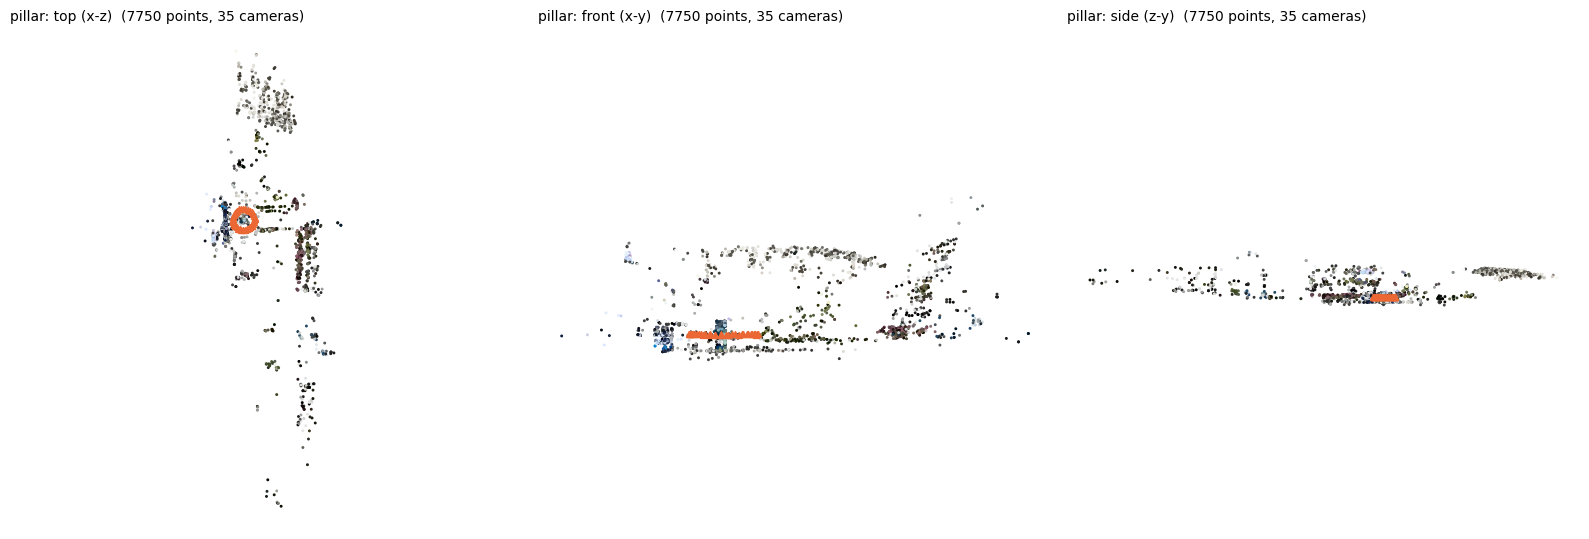

figures saved to /content/drive/MyDrive/AI6121_SfM/generalization/figures
point clouds (open in MeshLab / CloudCompare): /content/drive/MyDrive/AI6121_SfM/generalization/SfM_stage6/<scene>/points.ply


In [ ]:
# Renders for the report: coloured sparse cloud + camera ring from three directions (saved to Drive/figures)
os.makedirs(f"{PROJECT}/figures", exist_ok=True)
for s in M:
    z = np.load(f"{OUT}/{s}/model.npz", allow_pickle=True)
    X, rgb, reg = z["X"], z["rgb"], z["registered"]
    Cc = -np.einsum("nji,nj->ni", z["R"], z["t"])[reg]
    lo, hi = np.percentile(X, [1, 99], 0)
    keep = ((X > lo - 0.5 * (hi - lo)) & (X < hi + 0.5 * (hi - lo))).all(1)
    X, rgb = X[keep], rgb[keep] / 255.0
    views = [("top (x-z)", 0, 2), ("front (x-y)", 0, 1), ("side (z-y)", 2, 1)]
    fig, ax = plt.subplots(1, 3, figsize=(16, 5.5))
    for a, (name, i, j) in zip(ax, views):
        a.scatter(X[:, i], X[:, j], s=1.2, c=rgb)
        a.scatter(Cc[:, i], Cc[:, j], s=18, c="#eb6834", marker="^")
        a.set_title(f"{s}: {name}  ({keep.sum()} points, {reg.sum()} cameras)", fontsize=10, loc="left")
        a.set_aspect("equal", "datalim"); a.axis("off")
    plt.tight_layout()
    plt.savefig(f"{PROJECT}/figures/{s}_views.png", dpi=170)
    plt.show()
print("figures saved to", f"{PROJECT}/figures")
print("point clouds (open in MeshLab / CloudCompare):", f"{PROJECT}/SfM_stage6/<scene>/points.ply")